In [1]:
from TableToDict import GetDFv2, GetDF, DisplayColumns
from HuRI import GetHuRI
#from ccsblib import  huri
from Load_CCSB_Data import GetOrfMapping
from load_edgotyping_data import load_qY2H
import pandas as pd
import numpy as np

from matplotlib import pyplot as plt
import seaborn as sns

from PandasToMySQL import MakeSummaryTable

%matplotlib inline
%config InlineBackend.figure_format='retina'

pd.options.display.max_rows = 1000
pd.options.display.max_columns = 60

In [2]:
from PlateDict import wellMap

A01
31


In [3]:
from scipy.stats import pearsonr, spearmanr, shapiro, ttest_ind, ttest_rel

In [4]:
import glob
import xlrd

## Process data

In [5]:
xp1_mapping_d = {1:(1,1),   #plate number (1-69) (reader): retest_pla (1-23), replicate number (1-2-3)
                 2:(1,2),
                 3:(1,3),
                 4:(2,1),
                 5:(2,2),
                 6:(2,3),
                 7:(3,1),
                 8:(3,2),
                 9:(3,3),
                 10:(4,1),
                 11:(4,2),
                 12:(4,3),
                 13:(5,1),
                 14:(5,2),
                 15:(5,3),
                 16:(6,1),
                 17:(6,2),
                 18:(6,3),
                 19:(7,1),
                 20:(7,2),
                 21:(7,3),
                 22:(8,1),
                 23:(8,2),
                 24:(8,3),
                 25:(9,1),
                 26:(9,2),
                 27:(9,3),
                 28:(10,1),
                 29:(10,2),
                 30:(10,3),
                 31:(11,1),
                 32:(11,2),
                 33:(11,3),
                 34:(12,1),
                 35:(12,2),
                 36:(12,3),
                 37:(13,1),
                 38:(13,2),
                 39:(13,3),
                 40:(14,1),
                 41:(14,2),
                 42:(14,3),
                 43:(15,1),
                 44:(15,2),
                 45:(15,3),
                 46:(16,1),
                 47:(16,2),
                 48:(16,3),
                 49:(17,1),
                 50:(17,2),
                 51:(17,3),
                 52:(18,1),
                 53:(18,2),
                 54:(18,3),
                 55:(19,1),
                 56:(19,2),
                 57:(19,3),
                 58:(20,1),
                 59:(20,2),
                 60:(20,3),
                 61:(21,1),
                 62:(21,2),
                 63:(21,3),
                 64:(22,1),
                 65:(22,2),
                 66:(22,3),
                 67:(23,1),
                 68:(23,2),
                 69:(23,3)
                }

xp2_mapping_d = {1:(1,1),
                 2:(1,2),
                 3:(1,3),
                 4:(2,1),
                 5:(2,2),
                 6:(2,3),
                 7:(3,1),
                 8:(3,2),
                 9:(3,3),
                 10:(4,1),
                 11:(4,2),
                 12:(4,3),
                 13:(7,1),
                 14:(7,2),
                 15:(7,3),
                 16:(6,1),
                 17:(6,2),
                 18:(6,3),
                 19:(5,1),
                 20:(5,2),
                 21:(5,3),
                 22:(9,1),
                 23:(9,2),
                 24:(9,3),
                 25:(10,1),
                 26:(10,2),
                 27:(10,3),
                 28:(11,1),
                 29:(11,2),
                 30:(11,3),
                 31:(12,1),
                 32:(12,2),
                 33:(12,3),
                 34:(13,1),
                 35:(13,2),
                 36:(13,3),
                 37:(14,1),
                 38:(14,2),
                 39:(14,3),
                 40:(15,1),
                 41:(15,2),
                 42:(15,3),
                 43:(16,1),
                 44:(16,2),
                 45:(16,3),
                 46:(17,1),
                 47:(17,2),
                 48:(17,3),
                 49:(18,1),
                 50:(18,2),
                 51:(18,3),
                 52:(19,1),
                 53:(19,2),
                 54:(19,3),
                 55:(20,1),
                 56:(20,2),
                 57:(20,3),
                 58:(21,1),
                 59:(21,2),
                 60:(21,3),
                 61:(22,1), #plate is missing
                 62:(22,2),
                 63:(22,3),
                 64:(23,1),
                 65:(23,2),
                 66:(23,3),
                 67:(8,1),
                 68:(8,2),
                 69:(8,3)
                }

#xp1_mapping_d pla:pla_id,repeat
#xp2_mapping_d pla:pla_id,repeat

res = {'xp1':{1:{},2:{},3:{}},
       'xp2':{1:{},2:{},3:{}}
      }

for rep_id in ['1','2']:
    for i,elem in enumerate(glob.glob(f'2022_APWT_data/N2H_raw_replicat0{rep_id}/*')):

        pla = int(elem.split('-')[-1][1:-4])
        retest_pla, repeat = xp1_mapping_d[pla] if rep_id == '1' else xp2_mapping_d[pla]

        wb = xlrd.open_workbook(elem, encoding_override='ascii')  #ascii  #'iso-8859-1'
        df = pd.read_excel(wb, skiprows=24, skipfooter=0)
        if len(df) > 8:
            df = pd.read_excel(wb, skiprows=35, skipfooter=10)

        df.rename(columns={c:i+1 for i,c in enumerate(df.columns)}, inplace=True)

        value_d = dict()
        for l, (i, row) in zip(['A','B','C','D','E','F','G','H'], df.iterrows()):
            for i, value in enumerate(row):
                key = (retest_pla,f'{l}{str(i+1).zfill(2)}')

                res[f'xp{rep_id}'][repeat][key] = value

In [6]:
sc_df = pd.read_csv('../../../experiment_designs/20210320_mN2H_allele_pwt/VUS_mN2H_APWT_secret_code.csv')
sc_set = tuple(zip(sc_df.plate_id, sc_df.empty_well_1))
sc_df.head()

,plate_id,empty_well_1,empty_well_id1
0,1,H11,88
1,2,D03,20
2,3,B05,34
3,4,G11,87
4,5,B11,82


In [7]:
l = []
for xp in res.keys():
    for repeat in res[xp].keys():
        for (pla,well),rlu in res[xp][repeat].items():
            if well == 'H12' or (pla,well) in sc_set:
                l.append([xp,repeat,pla,well,rlu])
empty_well_df = pd.DataFrame(l, columns=['xp','r','pla','well','rlu'])

In [8]:
for xp in res:
    print(xp)

    for key in sc_set:
        try:
            print(f'Plate   {key[0]}\t{key[1]}\t RLU: {res[xp][1][key]} \t {res[xp][2][key]} \t {res[xp][3][key]}')
        except:
            try:
                print(f'Plate   {key[0]}\t{key[1]}\t RLU: \t\t {res[xp][2][key]} \t {res[xp][3][key]}')
            except:
                pass

xp1
Plate   1	H11	 RLU: 4286 	 5017 	 5741
Plate   2	D03	 RLU: 111 	 104 	 123
Plate   3	B05	 RLU: 86 	 86 	 117
Plate   4	G11	 RLU: 86 	 117 	 92
Plate   5	B11	 RLU: 129 	 221 	 239
Plate   6	E02	 RLU: 117 	 129 	 141
Plate   7	B06	 RLU: 258 	 381 	 399
Plate   8	B10	 RLU: 117 	 98 	 98
Plate   9	D01	 RLU: 160 	 522 	 485
Plate   10	E07	 RLU: 111 	 129 	 154
Plate   11	B02	 RLU: 141 	 325 	 344
Plate   12	F02	 RLU: 111 	 98 	 104
Plate   13	A03	 RLU: 135 	 154 	 147
Plate   14	A06	 RLU: 362 	 491 	 510
Plate   15	E08	 RLU: 135 	 98 	 111
Plate   16	B08	 RLU: 129 	 92 	 135
Plate   17	C04	 RLU: 464782 	 601138 	 684313
Plate   18	B04	 RLU: 178 	 178 	 221
Plate   19	A11	 RLU: 172 	 178 	 190
Plate   20	C06	 RLU: 196 	 270 	 270
Plate   21	G07	 RLU: 154 	 135 	 129
Plate   22	D02	 RLU: 2665 	 3408 	 4986
Plate   23	C09	 RLU: 104 	 98 	 80
xp2
Plate   1	H11	 RLU: 123 	 92 	 104
Plate   2	D03	 RLU: 123 	 123 	 123
Plate   3	B05	 RLU: 104 	 92 	 98
Plate   4	G11	 RLU: 160 	 160 	 160
Plate

### Retest DataFrame

In [9]:
col = ['ad_orf_id', 'ad_symbol', 'db_orf_id',
       'db_symbol', 'db_mut_id','variant_id', 'retest_pla', 'retest_pos', 
       'standard_batch']

q = f'select {", ".join(c for c in col)} from vus.retest where standard_batch = ("mN2Hapwtv2")'

retest_df = GetDFv2(q, col)
retest_df.rename(columns={c:c.replace('ad','N1').replace('db','N2') for c in retest_df.columns},inplace=True)

for xp in ['xp1','xp2']:
    for rep in [1,2,3]:
        retest_df[f'mN2H_{xp}r{rep}'] = [res[xp][rep][pla,pos] if (pla,pos) in res[xp][rep] else np.nan for pla,pos in zip(retest_df.retest_pla, retest_df.retest_pos)]

#discard measure if signal is 20% of those of 2 other replicates (it's never 5 fold more than the 2 other measures)    
retest_df['mN2H_xp1r1'] = [np.nan if r1/r2<0.2 and r1/r3<0.2 else r1 for r1,r2,r3 in zip(retest_df.mN2H_xp1r1, retest_df.mN2H_xp1r2, retest_df.mN2H_xp1r3)]
retest_df['mN2H_xp1r2'] = [np.nan if r2/r1<0.2 and r2/r3<0.2 else r2 for r1,r2,r3 in zip(retest_df.mN2H_xp1r1, retest_df.mN2H_xp1r2, retest_df.mN2H_xp1r3)]
retest_df['mN2H_xp1r3'] = [np.nan if r3/r2<0.2 and r3/r1<0.2 else r3 for r1,r2,r3 in zip(retest_df.mN2H_xp1r1, retest_df.mN2H_xp1r2, retest_df.mN2H_xp1r3)]
retest_df['mN2H_xp2r1'] = [np.nan if r1/r2<0.2 and r1/r3<0.2 else r1 for r1,r2,r3 in zip(retest_df.mN2H_xp2r1, retest_df.mN2H_xp2r2, retest_df.mN2H_xp2r3)]
retest_df['mN2H_xp2r2'] = [np.nan if r2/r1<0.2 and r2/r3<0.2 else r2 for r1,r2,r3 in zip(retest_df.mN2H_xp2r1, retest_df.mN2H_xp2r2, retest_df.mN2H_xp2r3)]
retest_df['mN2H_xp2r3'] = [np.nan if r3/r2<0.2 and r3/r1<0.2 else r3 for r1,r2,r3 in zip(retest_df.mN2H_xp2r1, retest_df.mN2H_xp2r2, retest_df.mN2H_xp2r3)]

xp_errors = {1:{(5,'E03')},
             2:{(5,'E03'),
                (13,'A05'),
                (13,'A06'),
                (13,'D06'),
                (14,'C01'),
                (14,'B04'),
                (14,'E06'),
                (14,'H06'),
                (14,'B08'),
                (14,'A10'),
               }
            }

retest_df['error1'] = [(p,w) in [(pla,well) for pla,well in xp_errors[1]] for p,w in zip(retest_df.retest_pla, retest_df.retest_pos)]
retest_df['error2'] = [(p,w) in [(pla,well) for pla,well in xp_errors[2]] for p,w in zip(retest_df.retest_pla, retest_df.retest_pos)]

retest_df['xp1'] = [np.mean([e for e in [r1,r2,r3] if e == e]) for r1,r2,r3 in zip(retest_df.mN2H_xp1r1, retest_df.mN2H_xp1r2, retest_df.mN2H_xp1r3)]
retest_df['xp2'] = [np.mean([e for e in [r1,r2,r3] if e == e]) for r1,r2,r3 in zip(retest_df.mN2H_xp2r1, retest_df.mN2H_xp2r2, retest_df.mN2H_xp2r3)]

retest_df['xp1'] = [xp1 if not error else np.nan for xp1,error in zip(retest_df.xp1, retest_df.error1)]
retest_df['xp2'] = [xp2 if not error else np.nan for xp2,error in zip(retest_df.xp2, retest_df.error2)]

retest_df.head()

,N1_orf_id,N1_symbol,N2_orf_id,N2_symbol,N2_mut_id,variant_id,retest_pla,retest_pos,standard_batch,mN2H_xp1r1,mN2H_xp1r2,mN2H_xp1r3,mN2H_xp2r1,mN2H_xp2r2,mN2H_xp2r3,error1,error2,xp1,xp2
0,1108,LCP2,5001,NCK1,0,PRS,1,A01,mN2Hapwtv2,1661477.0,2351162.0,2855875.0,3163425.0,3575482.0,4271657,False,False,2.289505e+06,3.670188e+06
1,0,None,5001,NCK1,0,empty_N1,1,B01,mN2Hapwtv2,159608.0,102775.0,137461.0,186214.0,208374.0,229324,False,False,1.332813e+05,2.079707e+05
2,1108,LCP2,0,None,0,empty_N2,1,C01,mN2Hapwtv2,72620.0,89714.0,54138.0,87449.0,113606.0,116952,False,False,7.215733e+04,1.060023e+05
3,617,SHMT2,4447,STAC3,0,RRS,1,D01,mN2Hapwtv2,33943.0,49969.0,52941.0,63533.0,68838.0,78785,False,False,4.561767e+04,7.038533e+04
4,0,None,4447,STAC3,0,empty_N1,1,E01,mN2Hapwtv2,11537.0,9880.0,12735.0,15277.0,16560.0,18936,False,False,1.138400e+04,1.692433e+04


### Normalized DF

In [10]:
empty_N1_xp1_d = dict(zip(zip(retest_df[retest_df.variant_id == 'empty_N1'].N2_orf_id,retest_df[retest_df.variant_id == 'empty_N1'].N2_mut_id),retest_df[retest_df.variant_id == 'empty_N1'].xp1))
empty_N2_xp1_d = dict(zip(retest_df[retest_df.variant_id == 'empty_N2'].N1_orf_id, retest_df[retest_df.variant_id == 'empty_N2'].xp1))

empty_N1_xp2_d = dict(zip(zip(retest_df[retest_df.variant_id == 'empty_N1'].N2_orf_id,retest_df[retest_df.variant_id == 'empty_N1'].N2_mut_id),retest_df[retest_df.variant_id == 'empty_N1'].xp2))
empty_N2_xp2_d = dict(zip(retest_df[retest_df.variant_id == 'empty_N2'].N1_orf_id, retest_df[retest_df.variant_id == 'empty_N2'].xp2))

normalized_df = retest_df[retest_df.variant_id.isin(['wt','RRS','PRS', 'allele'])].copy()

normalized_df.drop(columns=['error1','error2','mN2H_xp1r1','mN2H_xp1r2','mN2H_xp1r3','mN2H_xp2r1','mN2H_xp2r2','mN2H_xp2r3'], inplace=True)

normalized_df['empty_N1_xp1'] = normalized_df.apply(lambda x: empty_N1_xp1_d[x.N2_orf_id,x.N2_mut_id], axis=1)
normalized_df['empty_N2_xp1'] = normalized_df.N1_orf_id.map(empty_N2_xp1_d)

normalized_df['empty_N1_xp2'] = normalized_df.apply(lambda x: empty_N1_xp2_d[x.N2_orf_id,x.N2_mut_id], axis=1)
normalized_df['empty_N2_xp2'] = normalized_df.N1_orf_id.map(empty_N2_xp2_d)

normalized_df['max_ctrl_r1'] = [max([en1,en2]) for en1, en2 in zip(normalized_df.empty_N1_xp1, normalized_df.empty_N2_xp1)]
normalized_df['max_ctrl_r2'] = [max([en1,en2]) for en1, en2 in zip(normalized_df.empty_N1_xp2, normalized_df.empty_N2_xp2)]

normalized_df['NLR1'] = [N1N2/max([N1F2,N2F1]) for N1N2, N1F2, N2F1 in zip(normalized_df.xp1, normalized_df.empty_N1_xp1, normalized_df.empty_N2_xp1)]
normalized_df['NLR2'] = [N1N2/max([N1F2,N2F1]) for N1N2, N1F2, N2F1 in zip(normalized_df.xp2, normalized_df.empty_N1_xp2, normalized_df.empty_N2_xp2)]

d = {0:1,1:0}
normalized_df['repeat_ratio'] = [[nlr1,nlr2][i%2]/[nlr1,nlr2][d[(i%2)]] for i,(nlr1, nlr2) in enumerate(zip(normalized_df.NLR1, normalized_df.NLR2))]
normalized_df['repeat_ratio_log2'] = normalized_df.repeat_ratio.apply(np.log2)

#normalized_df['avg_NLR'] = [np.mean([e for e in [nlr1, nlr2] if e == e]) if nlr1 == nlr1 or nlr2 == nlr2 else np.nan for nlr1,nlr2 in zip(normalized_df.NLR1, normalized_df.NLR2)]
normalized_df['avg_NLR'] = [np.mean([nlr1, nlr2]) for nlr1,nlr2 in zip(normalized_df.NLR1, normalized_df.NLR2)]


# df = normalized_df[normalized_df.variant_id == 'RRS']
# normalized_df['zNLR1'] = normalized_df.NLR_xp1.apply(lambda x: (x-np.mean(df.NLR_xp1))/np.std(df.NLR_xp1))
# normalized_df['zNLR2'] = normalized_df.NLR_xp2.apply(lambda x: (x-np.mean(df.NLR_xp2))/np.std(df.NLR_xp2))

# normalized_df['NLR'] = normalized_df.apply(lambda x: np.mean([x.NLR_xp1, x.NLR_xp2]), axis=1)

normalized_df.head()

,N1_orf_id,N1_symbol,N2_orf_id,N2_symbol,N2_mut_id,variant_id,retest_pla,retest_pos,standard_batch,xp1,xp2,empty_N1_xp1,empty_N2_xp1,empty_N1_xp2,empty_N2_xp2,max_ctrl_r1,max_ctrl_r2,NLR1,NLR2,repeat_ratio,repeat_ratio_log2,avg_NLR
0,1108,LCP2,5001,NCK1,0,PRS,1,A01,mN2Hapwtv2,2.289505e+06,3.670188e+06,133281.333333,60561.000000,2.079707e+05,91601.333333,133281.333333,2.079707e+05,17.177984,17.647623,0.973388,-0.038913,17.412804
3,617,SHMT2,4447,STAC3,0,RRS,1,D01,mN2Hapwtv2,4.561767e+04,7.038533e+04,11384.000000,1559.666667,1.692433e+04,2437.666667,11384.000000,1.692433e+04,4.007174,4.158825,1.037845,0.053591,4.082999
6,3535,EMD,5887,ARMC1,0,RRS,1,G01,mN2Hapwtv2,1.125092e+06,1.508690e+06,59592.666667,65487.333333,1.110043e+05,89346.000000,65487.333333,1.110043e+05,17.180294,13.591274,1.264068,0.338074,15.385784
9,3174,PDHB,7186,ZC3HC1,0,RRS,1,B02,mN2Hapwtv2,3.247837e+05,6.428973e+05,840605.666667,445242.333333,1.126690e+06,928918.000000,840605.666667,1.126690e+06,0.386369,0.570607,1.476846,0.562520,0.478488
12,273,FKBP3,5046,NQO2,0,RRS,1,E02,mN2Hapwtv2,5.132370e+05,8.464307e+05,27121.333333,64519.000000,5.824200e+04,77501.666667,64519.000000,7.750167e+04,7.954820,10.921451,0.728367,-0.457263,9.438135


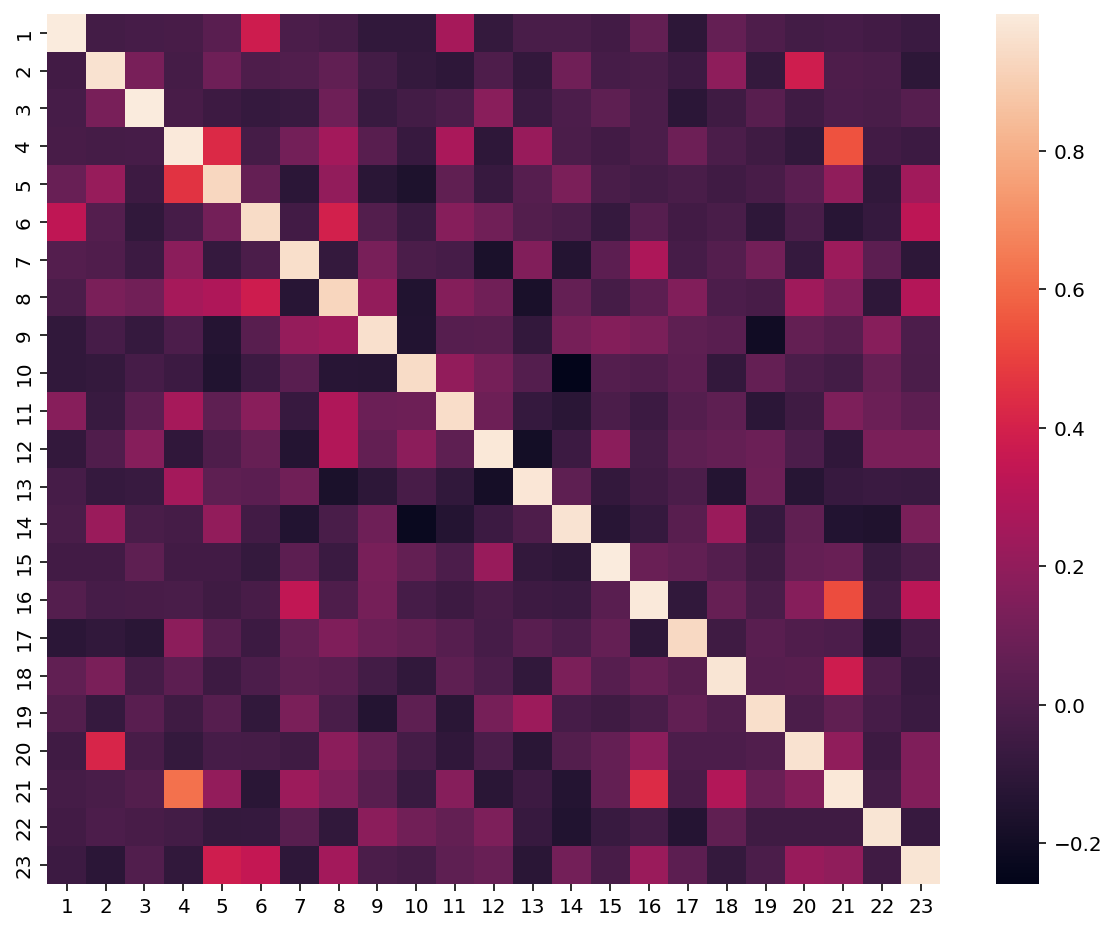

In [11]:
hm_res = {i:{} for i in range(1,24)}

for pla_i in range(1,24):
    for pla_j in range(1,24):
   
        
        common_wells = set(retest_df[(retest_df.retest_pla == pla_i)&(~retest_df.xp1.isnull())&(~retest_df.xp2.isnull())].retest_pos)&set(retest_df[(retest_df.retest_pla == pla_j)&(~retest_df.xp1.isnull())&(~retest_df.xp2.isnull())].retest_pos)
        
        a = retest_df[(retest_df.retest_pla == pla_i)&(retest_df.retest_pos.isin(common_wells))].xp1
        b = retest_df[(retest_df.retest_pla == pla_j)&(retest_df.retest_pos.isin(common_wells))].xp2
        
        pearson_corr = pearsonr(a, b)
        #print(pla_i,pla_j,pearson_corr)
        
        hm_res[pla_i][pla_j] = pearson_corr[0]

plt.figure(figsize=(10,8))
sns.heatmap(pd.DataFrame(hm_res));

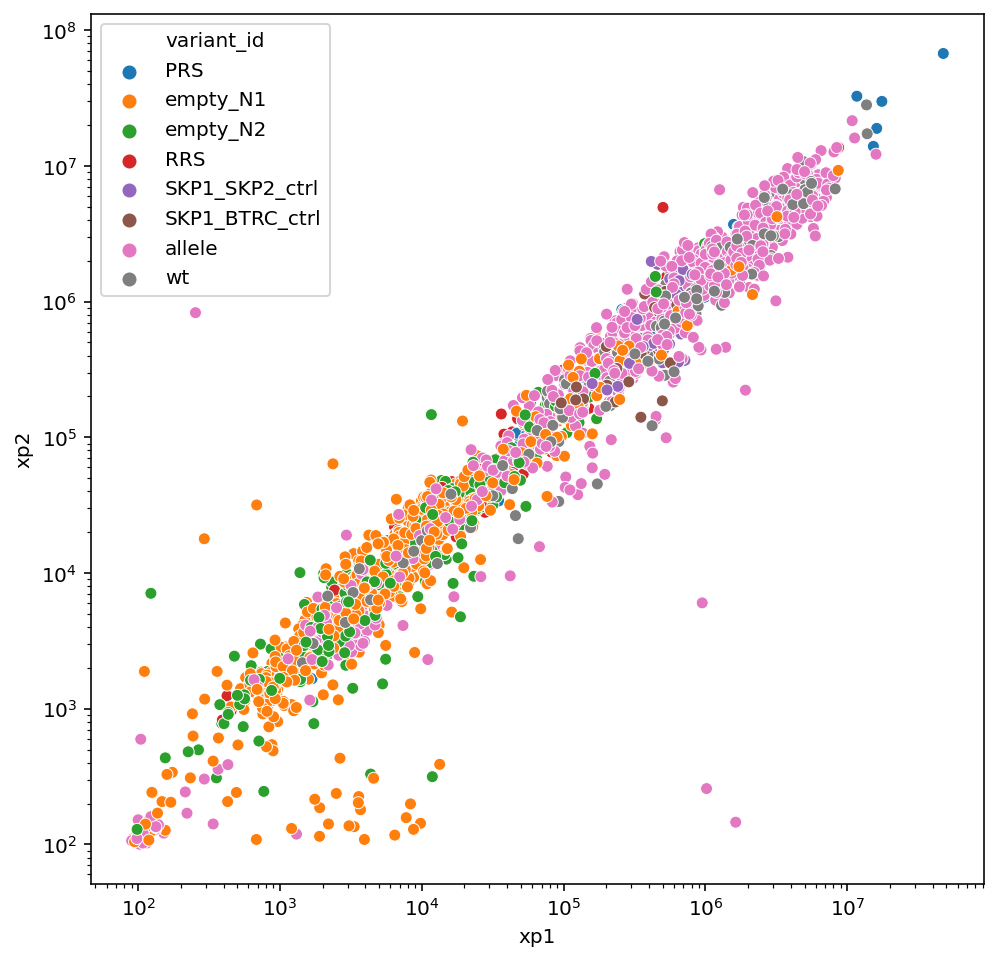

In [12]:
plt.figure(figsize=(8,8))
sns.scatterplot(data=retest_df, x='xp1',y='xp2',hue='variant_id');
plt.xscale('log')
plt.yscale('log')

## Empty wells

In [13]:
empty_well_df.head()

,xp,r,pla,well,rlu
0,xp1,1,15,E08,135
1,xp1,1,15,H12,117
2,xp1,1,14,A06,362
3,xp1,1,14,H12,111
4,xp1,1,19,A11,172


<AxesSubplot:xlabel='rlu', ylabel='Count'>

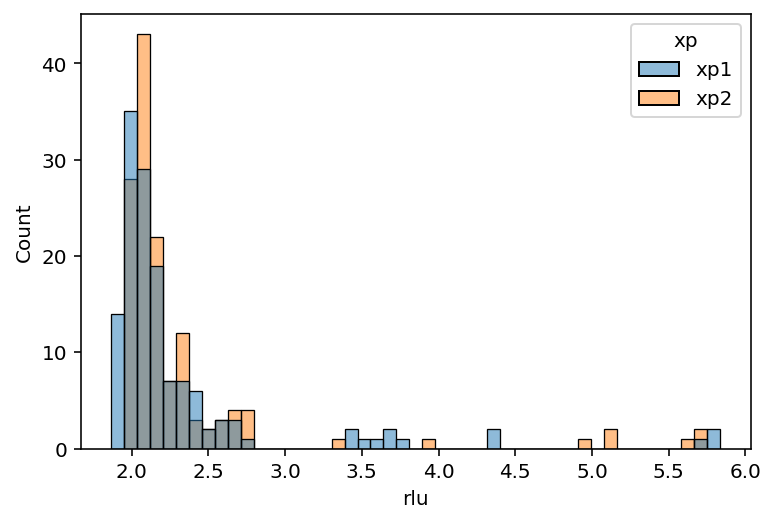

In [14]:
sns.histplot(data=empty_well_df, x=empty_well_df.rlu.apply(np.log10), hue='xp')

## Empty control distribution

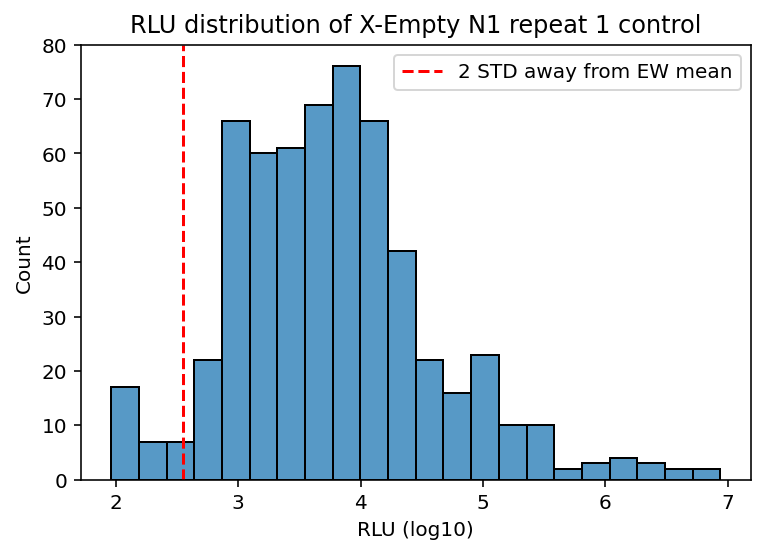

In [15]:
mean_empty = np.mean(empty_well_df[empty_well_df.rlu < 1000].rlu)
std_empty = np.std(empty_well_df[empty_well_df.rlu < 1000].rlu)

plt.figure()
plt.title('RLU distribution of X-Empty N1 repeat 1 control')
sns.histplot(x=retest_df[(retest_df.variant_id == 'empty_N1')].xp1.apply(np.log10))
plt.vlines(x=np.log10((2*std_empty)+mean_empty), ymin=0, ymax=80, linestyles = '--', color='r', label='2 STD away from EW mean')
plt.ylim(0,80)
plt.xlabel('RLU (log10)')
plt.legend()
plt.show()

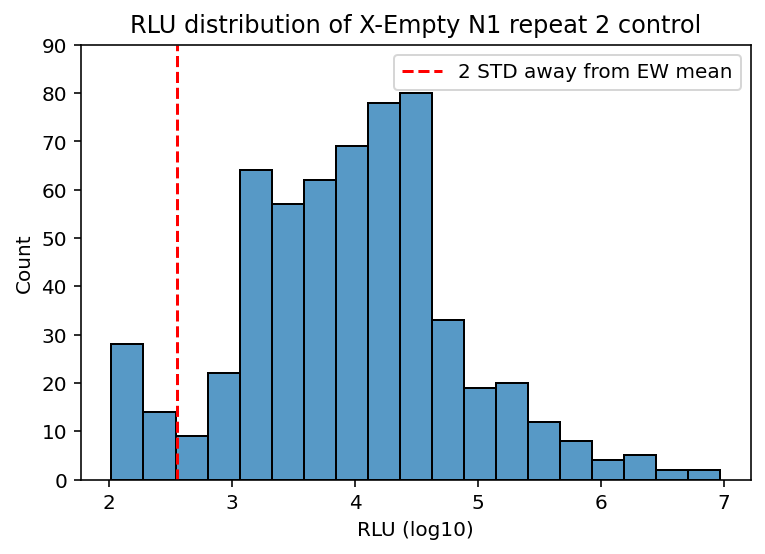

In [16]:
mean_empty = np.mean(empty_well_df[empty_well_df.rlu < 1000].rlu)
std_empty = np.std(empty_well_df[empty_well_df.rlu < 1000].rlu)

plt.figure()
plt.title('RLU distribution of X-Empty N1 repeat 2 control')
sns.histplot(x=retest_df[(retest_df.variant_id == 'empty_N1')].xp2.apply(np.log10))
plt.vlines(x=np.log10((2*std_empty)+mean_empty), ymin=0, ymax=90, linestyles = '--', color='r', label='2 STD away from EW mean')
plt.ylim(0,90)
plt.xlabel('RLU (log10)')
plt.legend()
plt.show()

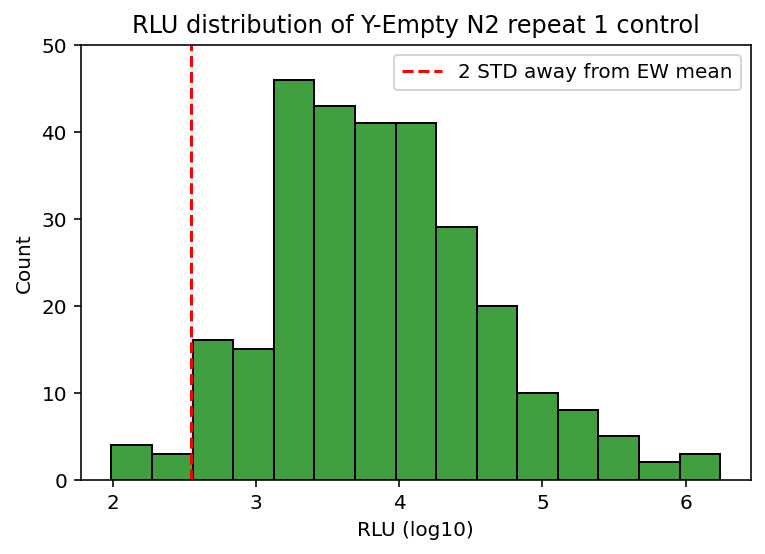

In [17]:
mean_empty = np.mean(empty_well_df[empty_well_df.rlu < 1000].rlu)
std_empty = np.std(empty_well_df[empty_well_df.rlu < 1000].rlu)

plt.figure()
plt.title('RLU distribution of Y-Empty N2 repeat 1 control')
sns.histplot(x=retest_df[(retest_df.variant_id == 'empty_N2')].xp1.apply(np.log10),color='green')
plt.vlines(x=np.log10((2*std_empty)+mean_empty), ymin=0, ymax=50, linestyles = '--', color='r', label='2 STD away from EW mean')
plt.ylim(0,50)
plt.xlabel('RLU (log10)')
plt.legend()
plt.show()

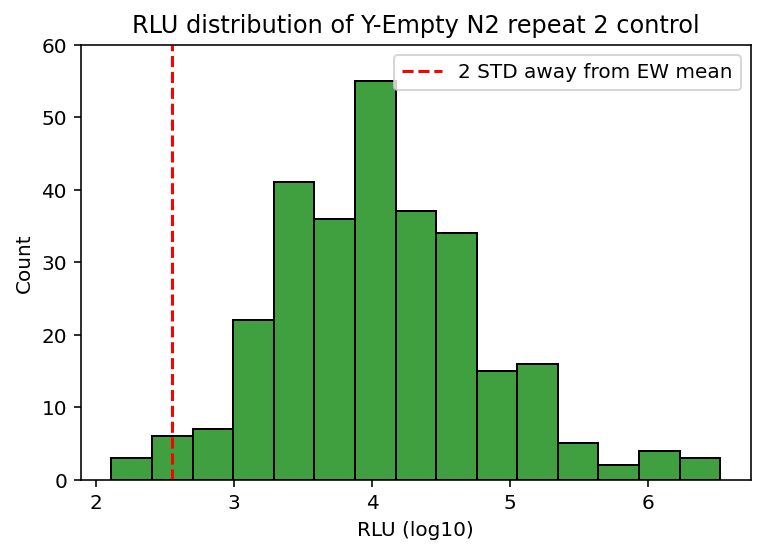

In [18]:
mean_empty = np.mean(empty_well_df[empty_well_df.rlu < 1000].rlu)
std_empty = np.std(empty_well_df[empty_well_df.rlu < 1000].rlu)

plt.figure()
plt.title('RLU distribution of Y-Empty N2 repeat 2 control')
sns.histplot(x=retest_df[(retest_df.variant_id == 'empty_N2')].xp2.apply(np.log10),color='green')
plt.vlines(x=np.log10((2*std_empty)+mean_empty), ymin=0, ymax=60, linestyles = '--', color='r', label='2 STD away from EW mean')
plt.ylim(0,60)
plt.xlabel('RLU (log10)')
plt.legend()
plt.show()

## PRS-RRS reproducibility

In [19]:
normalized_df.head()

,N1_orf_id,N1_symbol,N2_orf_id,N2_symbol,N2_mut_id,variant_id,retest_pla,retest_pos,standard_batch,xp1,xp2,empty_N1_xp1,empty_N2_xp1,empty_N1_xp2,empty_N2_xp2,max_ctrl_r1,max_ctrl_r2,NLR1,NLR2,repeat_ratio,repeat_ratio_log2,avg_NLR
0,1108,LCP2,5001,NCK1,0,PRS,1,A01,mN2Hapwtv2,2.289505e+06,3.670188e+06,133281.333333,60561.000000,2.079707e+05,91601.333333,133281.333333,2.079707e+05,17.177984,17.647623,0.973388,-0.038913,17.412804
3,617,SHMT2,4447,STAC3,0,RRS,1,D01,mN2Hapwtv2,4.561767e+04,7.038533e+04,11384.000000,1559.666667,1.692433e+04,2437.666667,11384.000000,1.692433e+04,4.007174,4.158825,1.037845,0.053591,4.082999
6,3535,EMD,5887,ARMC1,0,RRS,1,G01,mN2Hapwtv2,1.125092e+06,1.508690e+06,59592.666667,65487.333333,1.110043e+05,89346.000000,65487.333333,1.110043e+05,17.180294,13.591274,1.264068,0.338074,15.385784
9,3174,PDHB,7186,ZC3HC1,0,RRS,1,B02,mN2Hapwtv2,3.247837e+05,6.428973e+05,840605.666667,445242.333333,1.126690e+06,928918.000000,840605.666667,1.126690e+06,0.386369,0.570607,1.476846,0.562520,0.478488
12,273,FKBP3,5046,NQO2,0,RRS,1,E02,mN2Hapwtv2,5.132370e+05,8.464307e+05,27121.333333,64519.000000,5.824200e+04,77501.666667,64519.000000,7.750167e+04,7.954820,10.921451,0.728367,-0.457263,9.438135


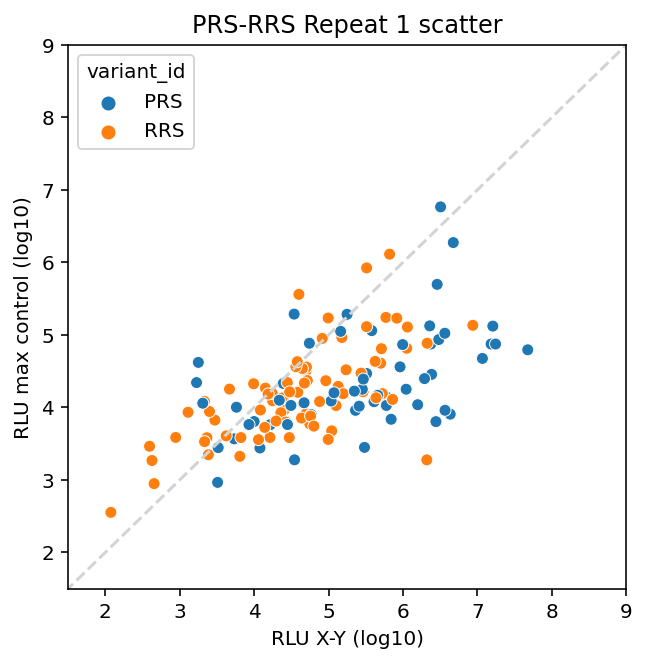

In [20]:
df = normalized_df[normalized_df.variant_id.isin(['PRS','RRS'])]

plt.figure(figsize=(5,5))
plt.title('PRS-RRS Repeat 1 scatter')
sns.scatterplot(data=df, 
                y=df.max_ctrl_r1.apply(np.log10), 
                x=df.xp1.apply(np.log10),
                hue='variant_id'
               )

plt.xlim(1.5,9)
plt.ylim(1.5,9)

plt.xlabel('RLU X-Y (log10)')
plt.ylabel('RLU max control (log10)')

plt.plot([1,12],[1,12], linestyle='--', color='lightgray')

#plt.vlines(x=np.log10((2*std_r2)+mean_r2),ymin=0, ymax=550, color='r', label='Two STD away from empty well mean', linestyle='--',alpha=0.5)
#plt.hlines(y=np.log10((2*std_r2)+mean_r2),xmin=0, xmax=550, color='r', label='Two STD away from empty well mean', linestyle='--',alpha=0.5)


plt.show()

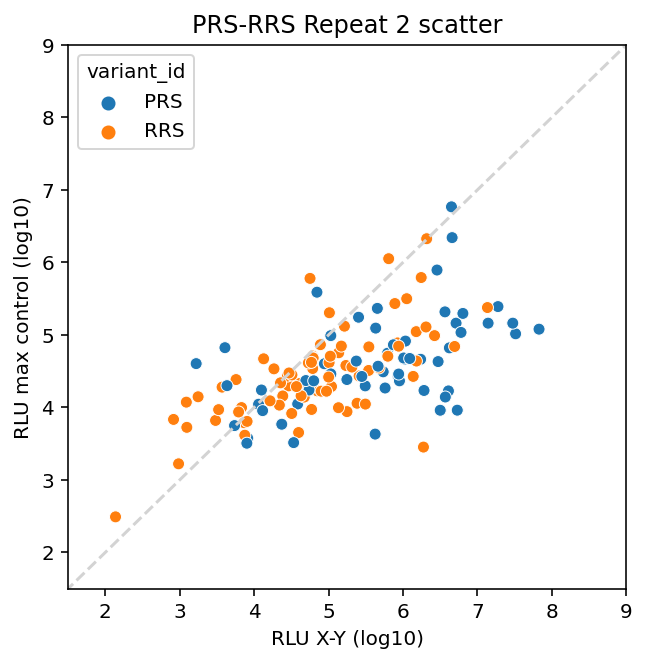

In [21]:
df = normalized_df[normalized_df.variant_id.isin(['PRS','RRS'])]

plt.figure(figsize=(5,5))
plt.title('PRS-RRS Repeat 2 scatter')
sns.scatterplot(data=df, 
                y=df.max_ctrl_r2.apply(np.log10), 
                x=df.xp2.apply(np.log10),
                hue='variant_id'
               )

plt.xlim(1.5,9)
plt.ylim(1.5,9)

plt.xlabel('RLU X-Y (log10)')
plt.ylabel('RLU max control (log10)')

plt.plot([1,12],[1,12], linestyle='--', color='lightgray')

#plt.vlines(x=np.log10((2*std_r2)+mean_r2),ymin=0, ymax=550, color='r', label='Two STD away from empty well mean', linestyle='--',alpha=0.5)
#plt.hlines(y=np.log10((2*std_r2)+mean_r2),xmin=0, xmax=550, color='r', label='Two STD away from empty well mean', linestyle='--',alpha=0.5)


plt.show()

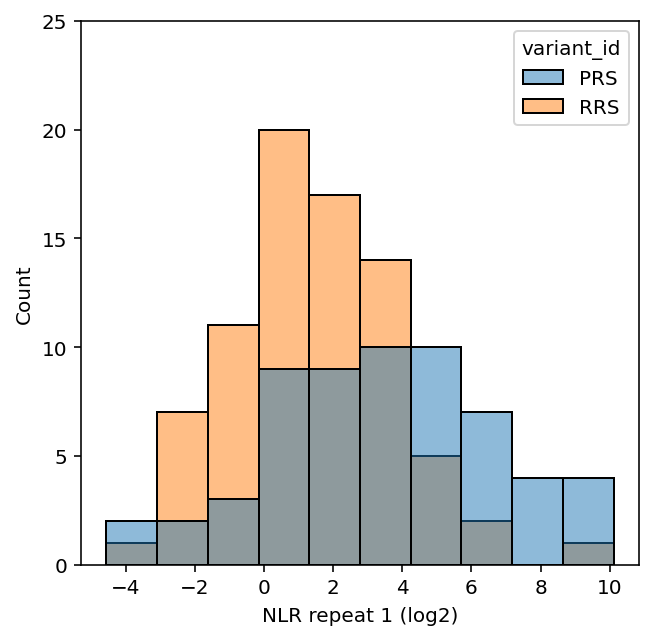

In [22]:
df = normalized_df[normalized_df.variant_id.isin(['PRS','RRS'])]

plt.figure(figsize=(5,5))

sns.histplot(data=df, 
                x=df.NLR1.apply(np.log2), hue='variant_id'
               )

# mean_nlr_rrs_r1
# mean_nlr_rrs_r2
# std_nlr_rrs_r1
# std_nlr_rrs_r2

#plt.vlines(x=np.log2((2.23*std_nlr_rrs_r1)+mean_nlr_rrs_r1),ymin=0, ymax=550, color='r', label='2.23 STD away from empty well mean', linestyle='--',alpha=0.5)
#plt.vlines(x=np.log2(2),ymin=0, ymax=550, color='r', label='2.23 STD away from empty well mean', linestyle='--',alpha=0.5)


#plt.xlim(-8,9.5)
plt.ylim(0,25)
plt.xlabel('NLR repeat 1 (log2)')

plt.show()

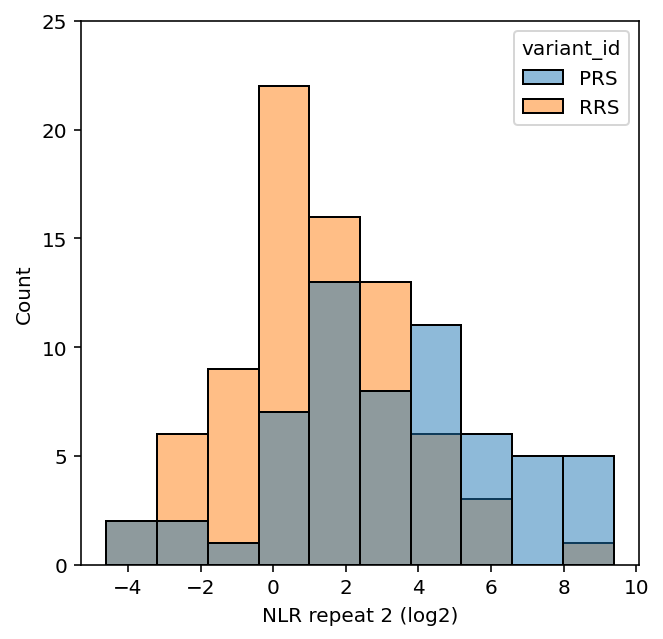

In [23]:
df = normalized_df[normalized_df.variant_id.isin(['PRS','RRS'])]

plt.figure(figsize=(5,5))

sns.histplot(data=df, 
                x=df.NLR2.apply(np.log2), hue='variant_id'
               )

# mean_nlr_rrs_r1
# mean_nlr_rrs_r2
# std_nlr_rrs_r1
# std_nlr_rrs_r2

#plt.vlines(x=np.log2((2.23*std_nlr_rrs_r1)+mean_nlr_rrs_r1),ymin=0, ymax=550, color='r', label='2.23 STD away from empty well mean', linestyle='--',alpha=0.5)
#plt.vlines(x=np.log2(2),ymin=0, ymax=550, color='r', label='2.23 STD away from empty well mean', linestyle='--',alpha=0.5)


#plt.xlim(-8,9.5)
plt.ylim(0,25)
plt.xlabel('NLR repeat 2 (log2)')

plt.show()

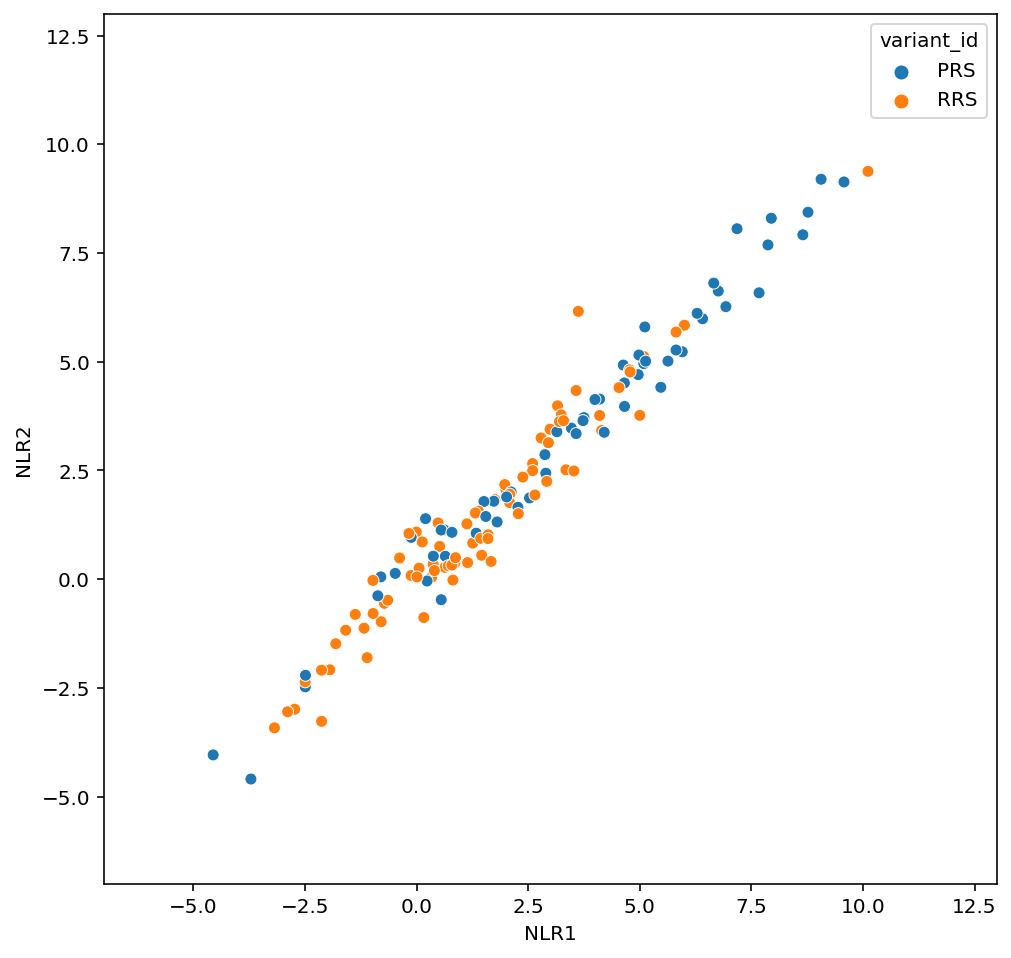

In [24]:
plt.figure(figsize=(8,8))
sns.scatterplot(data=normalized_df[normalized_df.variant_id.isin(['PRS','RRS'])], x=normalized_df.NLR1.apply(np.log2),y=normalized_df.NLR2.apply(np.log2),hue='variant_id');
plt.xlim(-7,13);
plt.ylim(-7,13);

(-15.0, 14.0)

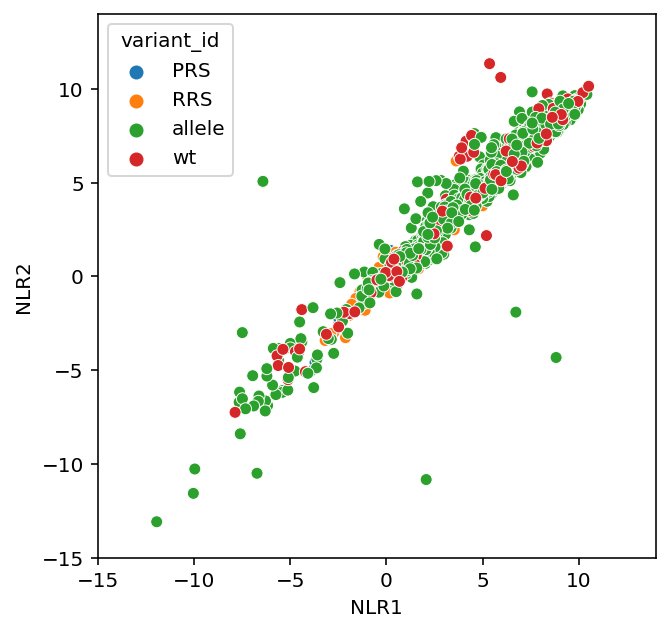

In [25]:
plt.figure(figsize=(5,5))
sns.scatterplot(data=normalized_df, x=normalized_df.NLR1.apply(np.log2),y=normalized_df.NLR2.apply(np.log2), hue='variant_id')

plt.xlim(-15,14)
plt.ylim(-15,14)

<AxesSubplot:ylabel='Frequency'>

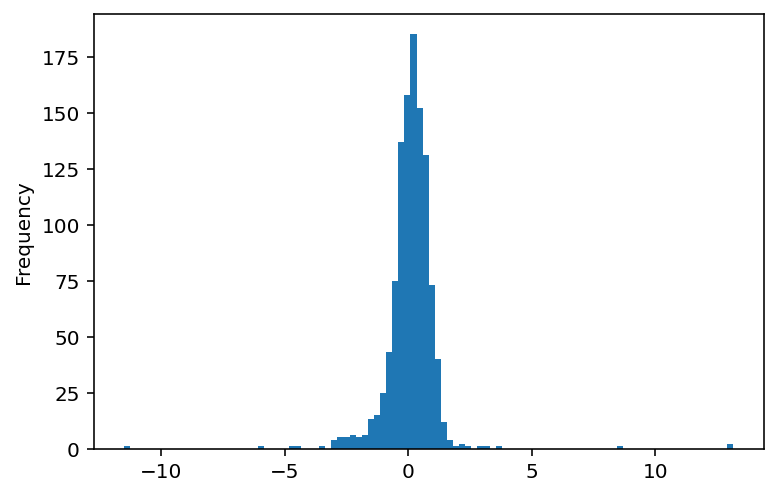

In [26]:
(normalized_df.NLR1 / normalized_df.NLR2).apply(np.log2).plot.hist(bins=100)

1.0666135630928595 -0.00407331004065015


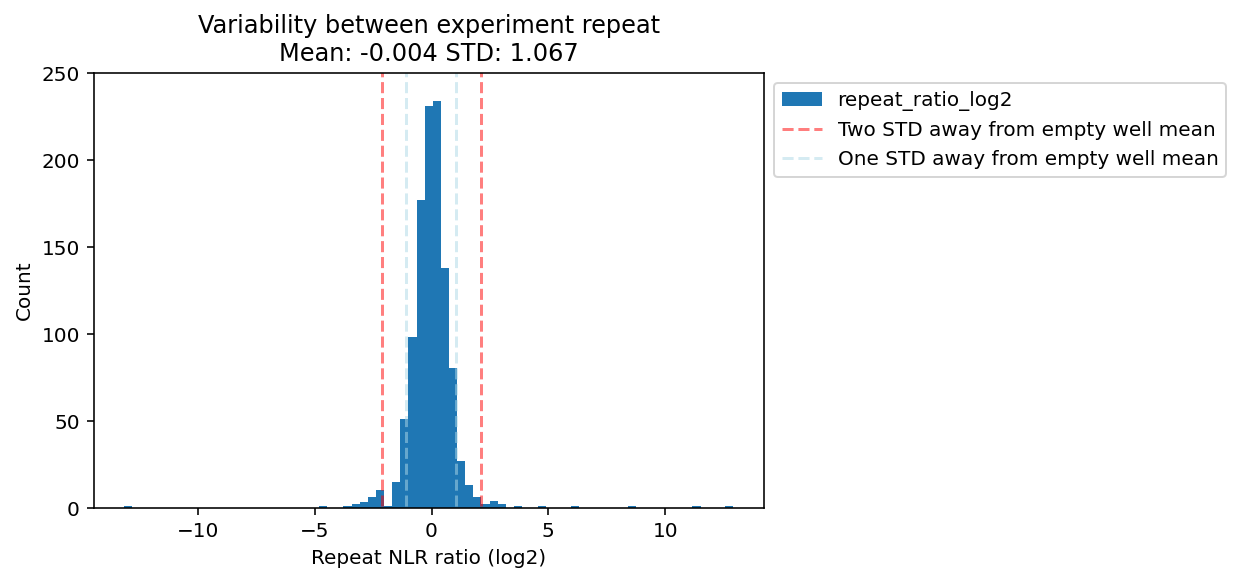

In [27]:
std_ratio = np.std(normalized_df.repeat_ratio_log2)
mean_ratio = np.mean(normalized_df.repeat_ratio_log2)

print(std_ratio,mean_ratio)

plt.figure()
plt.title(f'Variability between experiment repeat\nMean: {round(mean_ratio,3)} STD: {round(std_ratio,3)}')
fig = normalized_df.repeat_ratio_log2.plot.hist(bins=75)
plt.xlabel('Repeat NLR ratio (log2)')
plt.ylabel('Count')

plt.vlines(x=(2*std_ratio)+mean_ratio,ymin=-8, ymax=550, color='r', linestyle='--',alpha=0.5)
plt.vlines(x=(-2*std_ratio)+mean_ratio,ymin=-8, ymax=550, color='r', label='Two STD away from empty well mean', linestyle='--',alpha=0.5)

plt.vlines(x=(1*std_ratio)+mean_ratio,ymin=-8, ymax=550, color='lightblue', linestyle='--',alpha=0.5)
plt.vlines(x=(-1*std_ratio)+mean_ratio,ymin=-8, ymax=550, color='lightblue', label='One STD away from empty well mean', linestyle='--',alpha=0.5)


plt.ylim(0,250)
plt.legend(loc='upper left',bbox_to_anchor=(1, 1))

plt.show()

1.1224972282512644 -0.019208461751054798


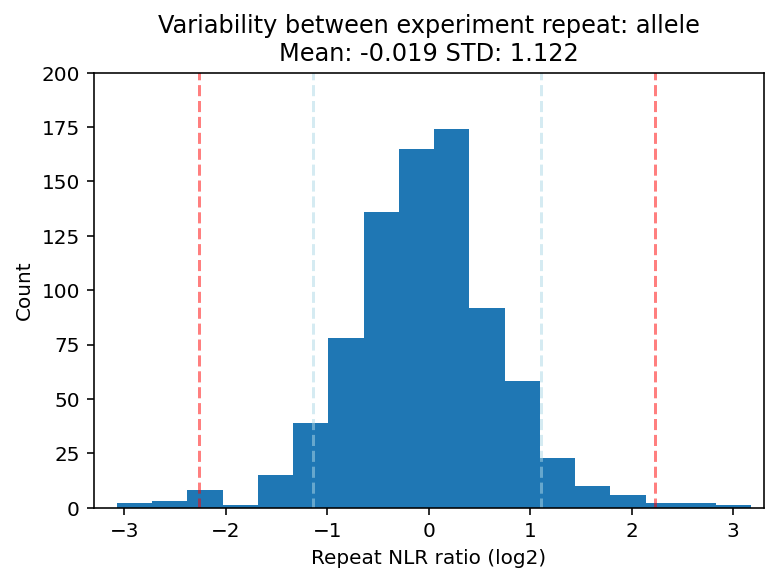

1.0945489980294538 0.044181194363445773


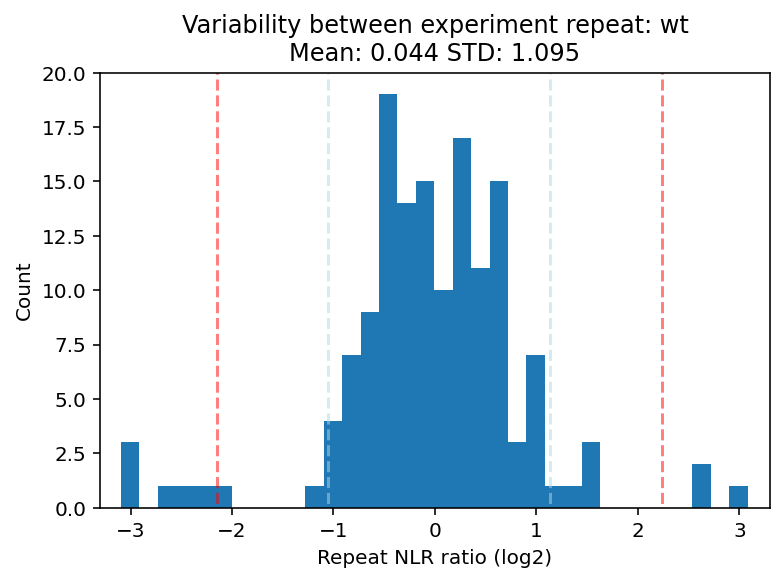

0.5221331161553674 0.008613045538913296


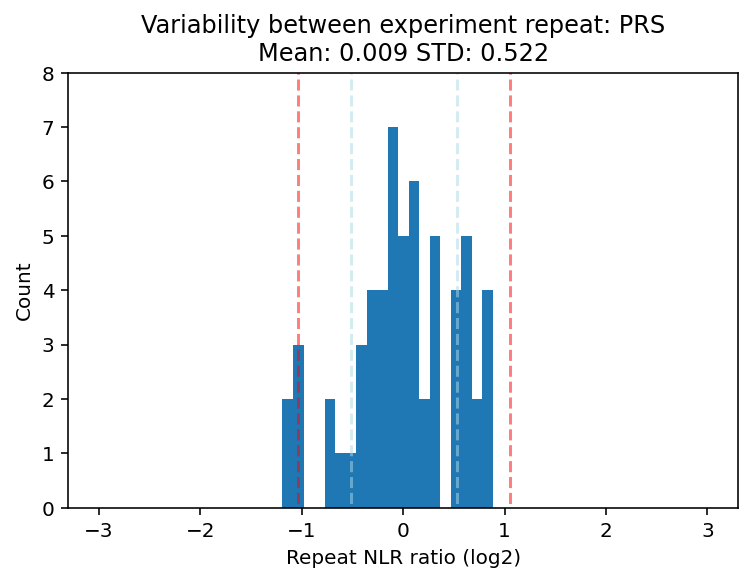

0.6230772410287004 0.0534906927153566


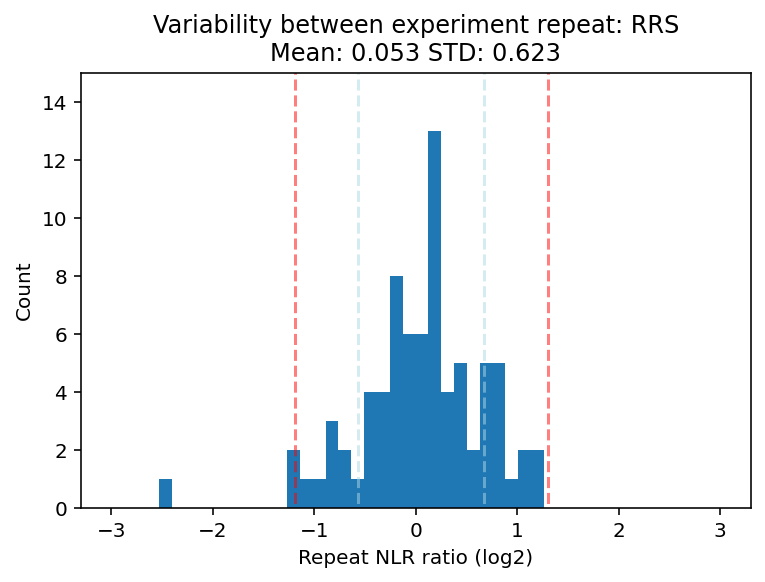

In [28]:
for ylim, variant_id,bins in zip([200,20,8,15],['allele','wt','PRS','RRS'],[75,50,20,30]):
    std_ratio = np.std(normalized_df[normalized_df.variant_id == variant_id].repeat_ratio_log2)
    mean_ratio = np.mean(normalized_df[normalized_df.variant_id == variant_id].repeat_ratio_log2)

    print(std_ratio,mean_ratio)

    plt.figure()
    plt.title(f'Variability between experiment repeat: {variant_id}\nMean: {round(mean_ratio,3)} STD: {round(std_ratio,3)}')
    fig = normalized_df[normalized_df.variant_id == variant_id].repeat_ratio_log2.plot.hist(bins=bins)
    plt.xlabel('Repeat NLR ratio (log2)')
    plt.ylabel('Count')

    plt.vlines(x=(2*std_ratio)+mean_ratio,ymin=-8, ymax=550, color='r', linestyle='--',alpha=0.5)
    plt.vlines(x=(-2*std_ratio)+mean_ratio,ymin=-8, ymax=550, color='r', label='Two STD away from empty well mean', linestyle='--',alpha=0.5)

    plt.vlines(x=(1*std_ratio)+mean_ratio,ymin=-8, ymax=550, color='lightblue', linestyle='--',alpha=0.5)
    plt.vlines(x=(-1*std_ratio)+mean_ratio,ymin=-8, ymax=550, color='lightblue', label='One STD away from empty well mean', linestyle='--',alpha=0.5)



    plt.ylim(0,ylim)
    plt.xlim(-3.3,3.3)
    
    #plt.legend(loc='upper left',bbox_to_anchor=(1, 1))

    plt.show()

### Allele WT DF

In [29]:
#mean NLR
#allele-wt ratio
#z-score perturbation

#two metrics: detection (above RRS, noise) + perturbation quantification allele/wt zscore
#NA if not 


allele_df = normalized_df.query("variant_id == 'allele' and ~avg_NLR.isnull()").copy()
#allele_df['nt_change'] = [mut_d[orf_id,mut_id][0] for orf_id, mut_id in zip(allele_df.N1_orf_id, allele_df.N1_mut_id)]
#allele_df['aa_change'] = [mut_d[orf_id,mut_id][1] for orf_id, mut_id in zip(allele_df.N1_orf_id, allele_df.N1_mut_id)]
#allele_df['clinical_significance'] = [mut_d[orf_id,mut_id][2] for orf_id, mut_id in zip(allele_df.N1_orf_id, allele_df.N1_mut_id)]

df = normalized_df.query("variant_id == 'wt'")
wt_NLR_d = dict(zip(df.N2_orf_id, df.avg_NLR))
allele_df['avg_WT_NLR'] = allele_df.N2_orf_id.map(wt_NLR_d)
allele_df = allele_df[~allele_df.avg_WT_NLR.isnull()].copy() #remove only one allele-WT
allele_df['AWT_ratio'] = allele_df.avg_NLR / allele_df.avg_WT_NLR

df = normalized_df.query("variant_id == 'RRS' and avg_NLR < 800")
l = [np.mean([nlr1,nlr2]) for nlr1,nlr2 in zip(df.NLR1, df.NLR2) if nlr1 == nlr1 and nlr2 == nlr2]
std_rrs, mean_rrs = np.std(l), np.mean(l)
allele_df['z_WT_NLR'] = allele_df.avg_WT_NLR.apply(lambda x: (x-mean_rrs)/std_rrs)
allele_df['WT_detected'] = allele_df.z_WT_NLR.apply(lambda x: x >= 2.23)

std_ratio = np.std(normalized_df.repeat_ratio_log2)
mean_ratio = np.mean(normalized_df.repeat_ratio_log2)
allele_df['z_perturbation'] = allele_df.AWT_ratio.apply(lambda x: (np.log2(x)-mean_ratio)/std_ratio)
#allele_df['z_cat'] = allele_df.z_perturbation.apply(lambda x: 'increase_ppi' if x>=3 else 'decrease_ppi' if x<=-3 else 'no_perturbation')
allele_df['z_cat'] = ['not_detected' if not wt_detected else 'increase_ppi' if zp>=2 else 'decrease_ppi' if zp<=-2 else 'no_perturbation' for zp,wt_detected in zip(allele_df.z_perturbation, allele_df.WT_detected)] 

allele_df.head()

,N1_orf_id,N1_symbol,N2_orf_id,N2_symbol,N2_mut_id,variant_id,retest_pla,retest_pos,standard_batch,xp1,xp2,empty_N1_xp1,empty_N2_xp1,empty_N1_xp2,empty_N2_xp2,max_ctrl_r1,max_ctrl_r2,NLR1,NLR2,repeat_ratio,repeat_ratio_log2,avg_NLR,avg_WT_NLR,AWT_ratio,z_WT_NLR,WT_detected,z_perturbation,z_cat
432,2838,TMEM248,9634,CLDN19,216880,allele,5,A08,mN2Hapwtv2,2.035600e+05,4.075393e+05,2407.000000,4271.666667,4750.333333,10035.333333,4271.666667,10035.333333,47.653531,40.610443,1.173430,0.230732,44.131987,15.997987,2.758596,0.785247,False,1.376326,not_detected
434,1198,TNFSF14,9634,CLDN19,216880,allele,5,C08,mN2Hapwtv2,6.880137e+05,1.203338e+06,2407.000000,6506.333333,4750.333333,8318.000000,6506.333333,8318.000000,105.745223,144.666787,0.730957,-0.452141,125.206005,15.997987,7.826360,0.785247,False,2.786778,not_detected
440,7201,RAD51D,13571,XRCC2,218098,allele,5,A09,mN2Hapwtv2,5.420693e+05,1.017460e+06,3153.666667,1393.500000,8012.666667,2703.666667,3153.666667,8012.666667,171.885424,126.981446,0.738756,-0.436829,149.433435,283.134878,0.527782,23.870236,True,-0.860586,no_perturbation
441,9955,FCGR1A,9634,CLDN19,216880,allele,5,B09,mN2Hapwtv2,7.062890e+05,1.799242e+06,2407.000000,1489.000000,4750.333333,5864.000000,2407.000000,5864.000000,293.431242,306.828502,0.956336,-0.064410,300.129872,15.997987,18.760478,0.785247,False,3.969289,not_detected
442,56141,KRT31,55855,KRT2,219419,allele,5,C09,mN2Hapwtv2,2.079383e+06,4.254541e+06,7365.500000,874.000000,19996.666667,1363.333333,7365.500000,19996.666667,282.313851,212.762494,0.753638,-0.408056,247.538172,11.465987,21.588912,0.393609,False,4.159231,not_detected


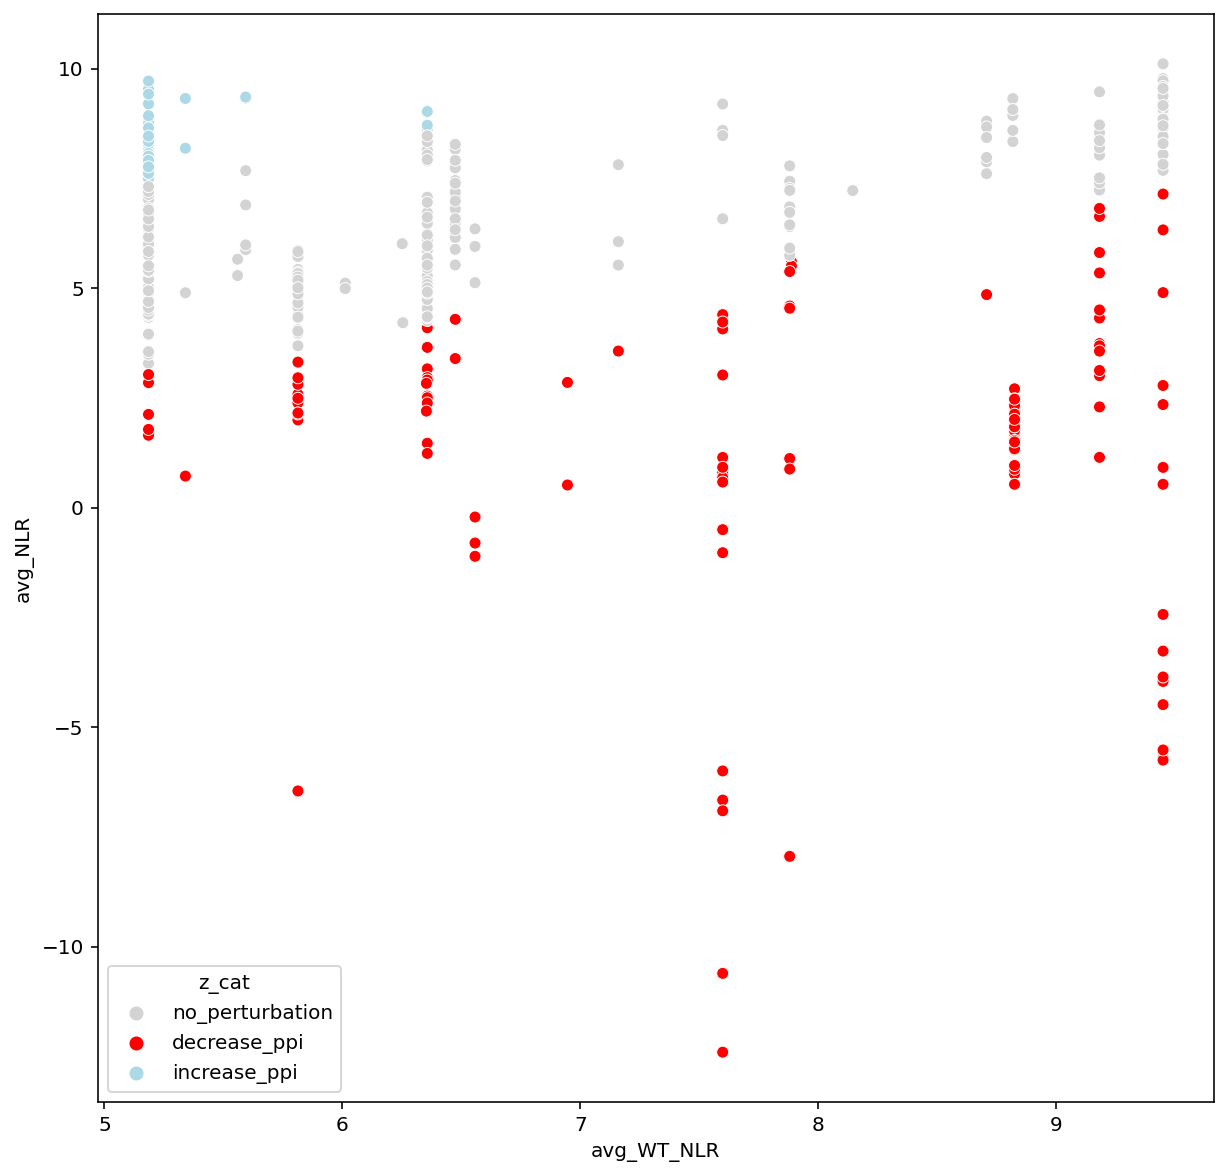

In [30]:
plt.figure(figsize=(10,10))
ax = sns.scatterplot(data=allele_df[allele_df.WT_detected ], x=allele_df.avg_WT_NLR.apply(np.log2), 
                     y=allele_df.avg_NLR.apply(np.log2), hue='z_cat',palette={'not_detected':'gray',
                                                                              'increase_ppi':'lightblue',
                                                                              'decrease_ppi':'red',
                                                                              'no_perturbation':'lightgray'}
                    )


#plt.xlim(-2,10)
#plt.ylim(-7,10)
plt.show()

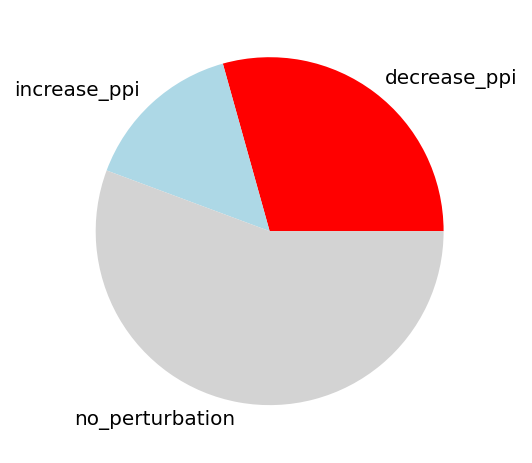

In [31]:
allele_df[allele_df.WT_detected].z_cat.value_counts().sort_index().plot.pie(colors=['red','lightblue','lightgray','gray']);
plt.ylabel('');

In [32]:
from load_pdest_stability import load_pdest_dataset

pdest_df = load_pdest_dataset()
pdest_d = {(orf_id,mut_id):(allele_wt_ratio,zscore,zcat) for orf_id,mut_id,allele_wt_ratio,zscore,zcat in zip(pdest_df.orf_id,
                                                                                                              pdest_df.mut_id,
                                                                                                              pdest_df.allele_wt_ratio,
                                                                                                              pdest_df.zscore,
                                                                                                              pdest_df.zcat,
                                                                                                             )}


pdest_df.head()

,avg_gfp,avg_mcherry,avg_GFP_mCherry_ratio,pla,well,coordinates,n_cells,orf_id,mut_id,node_type,nt_change,aa_change,clinical_significance,symbol,valid_well,z_pdest_empty,z_pdest_gfp,valid_gfp_mcherry_ratio,wt_GFP_mCherry_ratio,allele_wt_ratio,zscore,zcat
0,38.548163,7812.079547,0.010358,24,B07,"(24, 'B07')",8786,52920.0,2670.0,allele,388G>A,Gly130Ser,VUS,LITAF,True,-0.114591,-0.709508,NaN,NaN,NaN,NaN,0
1,651.596799,4750.119233,0.214581,8,A10,"(8, 'A10')",9387,3020.0,214471.0,allele,937G>A,Glu313Lys,Pathogenic,CHN1,True,11.094285,-0.075601,NaN,0.991226,0.216481,-2.711436,-2
2,1732.782852,6722.060197,0.365943,9,F01,"(9, 'F01')",8908,13113.0,21930.0,allele,427C>T,Arg143Cys,Conflicting,MCEE,True,19.401841,0.394226,NaN,0.448492,0.815940,-0.752219,0
3,481.091263,5965.903765,0.127281,22,D05,"(22, 'D05')",8739,4870.0,900200.0,allele,1567G>T,Val523Phe,NaN,KRT6A,True,6.302756,-0.346581,NaN,0.142704,0.891918,-0.503900,0
4,536.230753,1949.598159,0.395380,13,D07,"(13, 'D07')",8747,7652.0,1813.0,allele,875G>A,Arg292His,Pathogenic,STXBP1,True,21.017496,0.485598,NaN,NaN,NaN,NaN,0


In [33]:
mN2H_pert_d = {(db_orf_id,db_mut_id,ad_orf_id):(WT_detected,avg_NLR,avg_WT_NLR,AWT_ratio,z_perturbation,z_cat) 
               for db_orf_id,db_mut_id,ad_orf_id,WT_detected,avg_NLR,avg_WT_NLR,AWT_ratio,z_perturbation,z_cat 
               in zip(allele_df.N2_orf_id,allele_df.N2_mut_id,allele_df.N1_orf_id,
                      allele_df.WT_detected,allele_df.avg_NLR,allele_df.avg_WT_NLR,allele_df.AWT_ratio,allele_df.z_perturbation,allele_df.z_cat)
              }


big_table = pd.read_csv('../../nanoluc_Y2H/VUSAPWT_hsPRSRRSv2_Choi_Kd/edgotyping_y2h_n2h_pdest_table.tsv',sep='\t')
big_table['mN2H_AWT_r'] = [mN2H_pert_d[db_o,db_m,ad_o][3] if (db_o,db_m,ad_o) in mN2H_pert_d else np.nan for db_o,db_m,ad_o in zip(big_table.db_orf_id,big_table.db_mut_id,big_table.ad_orf_id)]
big_table['mN2H_WT_pos'] = [mN2H_pert_d[db_o,db_m,ad_o][0] if (db_o,db_m,ad_o) in mN2H_pert_d else np.nan for db_o,db_m,ad_o in zip(big_table.db_orf_id,big_table.db_mut_id,big_table.ad_orf_id)]
big_table['mN2H_pert_cat'] = [mN2H_pert_d[db_o,db_m,ad_o][-1] if (db_o,db_m,ad_o) in mN2H_pert_d else np.nan for db_o,db_m,ad_o in zip(big_table.db_orf_id,big_table.db_mut_id,big_table.ad_orf_id)]

pdest_df = load_pdest_dataset()
pdest_d = {(orf_id,mut_id):(allele_wt_ratio,zscore,zcat) for orf_id,mut_id,allele_wt_ratio,zscore,zcat in zip(pdest_df.orf_id,
                                                                                                              pdest_df.mut_id,
                                                                                                              pdest_df.allele_wt_ratio,
                                                                                                              pdest_df.zscore,
                                                                                                              pdest_df.zcat,
                                                                                                             )}

big_table['pdest_awr'] = [pdest_d[db,mut][0] if (db,mut) in pdest_d else np.nan  for db,mut in zip(big_table.db_orf_id, big_table.db_mut_id)]
big_table['pdest_zscore'] = [pdest_d[db,mut][1] if (db,mut) in pdest_d else np.nan  for db,mut in zip(big_table.db_orf_id, big_table.db_mut_id)]
big_table['pdest_zcat'] = [pdest_d[db,mut][2] if (db,mut) in pdest_d else np.nan  for db,mut in zip(big_table.db_orf_id, big_table.db_mut_id)]

big_table['WT_Allele_q3AT'] = [(wt,allele) for allele, wt in zip(big_table.q3AT, big_table.WT_q3AT)]

big_table.head()

,ad_orf_id,db_orf_id,orf_pair,db_mut_id,assay_id,LW,LWH1,LWH10,LWH25,LWA,LWAH1,sum_score,n_condition,allele_score_norm,wt_score_norm,valid,nt_change,aa_change,clinical_significance,db_symbol,ad_symbol,NLR,avg_NLR_mN2H,avg_NLR_yN2H,d_nanoY2H,pdest_ratio,pdest_zscore,pdest_zcat,d_mN2H,d_yN2H,d_ade,d_his1,d_his10,d_his25,q3AT,WT_q3AT,n_media_q3AT,n_syst,lit_bm,lit_bs,perturb_class,q_perturb,mN2H_AWT_r,mN2H_WT_pos,mN2H_pert_cat,pdest_awr,WT_Allele_q3AT
0,54326.0,7323.0,"(7323.0, 54326.0)",0.0,1.0,"[4.0, 4.0, True]","[3.0, 0.0, 1]","[2.0, 0.0, 1]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",2.0,5.0,0.4,0.4,True,WT,WT,WT,PMP22,EDA,-0.07968,1.370158,NaN,False,NaN,NaN,NaN,False,True,False,True,True,False,2.0,2.0,3.0,1,False,False,NP,0.0,NaN,NaN,NaN,NaN,"(2.0, 2.0)"
1,581.0,13295.0,"(13295.0, 581.0)",0.0,1.0,"[4.0, 4.0, True]","[2.0, 0.0, 1]","[2.0, 0.0, 1]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",2.0,5.0,0.4,0.4,True,WT,WT,WT,TTPA,MAL2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,False,False,True,True,False,2.0,2.0,3.0,0,False,False,NP,0.0,NaN,NaN,NaN,NaN,"(2.0, 2.0)"
2,869.0,13295.0,"(13295.0, 869.0)",0.0,1.0,"[4.0, 4.0, True]","[3.0, 0.0, 1]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",1.0,5.0,0.2,0.2,True,WT,WT,WT,TTPA,CMTM5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,False,False,True,False,False,1.0,1.0,3.0,0,False,False,NP,0.0,NaN,NaN,NaN,NaN,"(1.0, 1.0)"
3,7606.0,13295.0,"(13295.0, 7606.0)",0.0,1.0,"[4.0, 4.0, True]","[4.0, 0.0, 1]","[3.0, 0.0, 1]","[4.0, 0.0, 1]","[2.0, 0.0, 1]","[3.0, 0.0, 1]",5.0,5.0,1.0,1.0,True,WT,WT,WT,TTPA,BIRC7,NaN,NaN,0.57692,NaN,NaN,NaN,NaN,False,False,True,True,True,True,3.0,3.0,3.0,1,False,False,NP,0.0,NaN,NaN,NaN,NaN,"(3.0, 3.0)"
4,7845.0,13295.0,"(13295.0, 7845.0)",0.0,1.0,"[4.0, 4.0, True]","[3.0, 0.0, 1]","[3.0, 0.0, 1]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",2.0,5.0,0.4,0.4,True,WT,WT,WT,TTPA,AGTRAP,-0.65793,NaN,NaN,False,NaN,NaN,NaN,False,False,False,True,True,False,2.0,2.0,3.0,0,False,False,NP,0.0,NaN,NaN,NaN,NaN,"(2.0, 2.0)"


In [34]:
big_table[['ad_orf_id','db_orf_id','db_mut_id','mN2H_AWT_r','mN2H_WT_pos','mN2H_pert_cat']].to_csv('mN2H_res.csv', index=False)

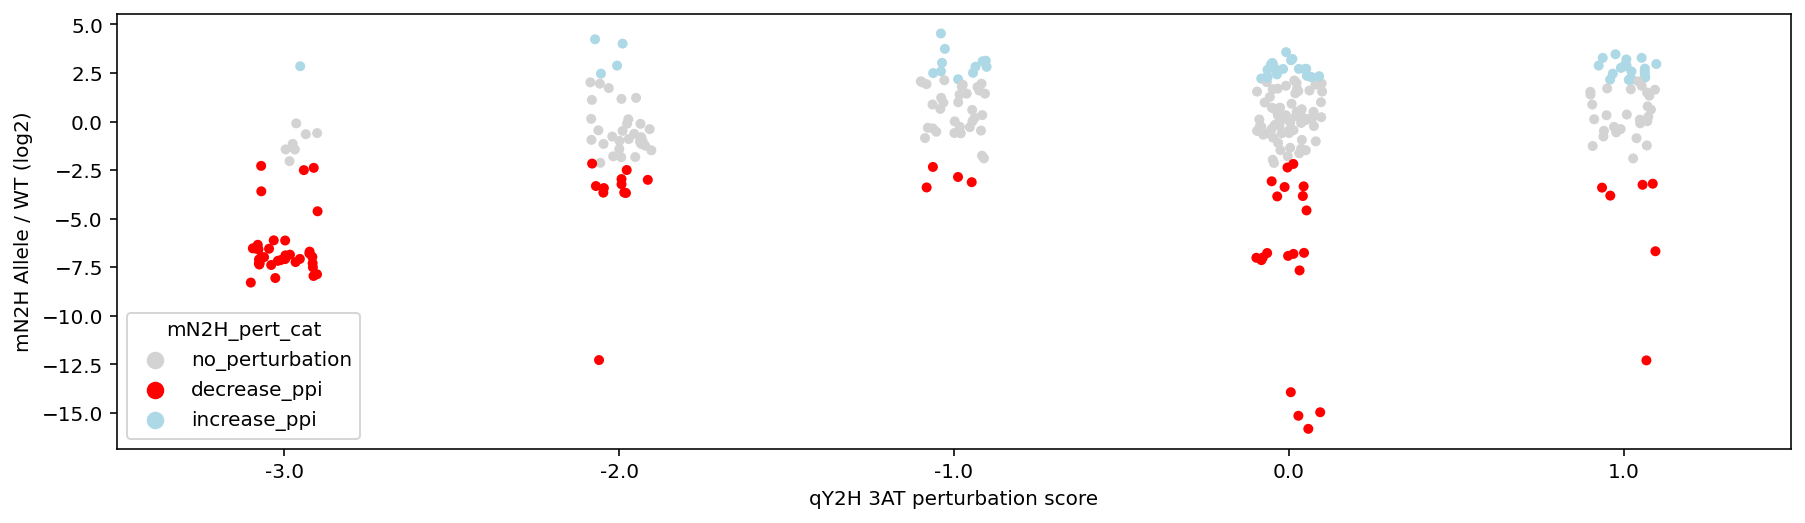

In [35]:
plt.figure(figsize=(15,4))
sns.stripplot(data=big_table[big_table.mN2H_WT_pos == True], x='q_perturb', y=big_table.mN2H_AWT_r.apply(np.log2), hue='mN2H_pert_cat', palette={'decrease_ppi':'red',
                                                                                                                                                 'increase_ppi':'lightblue',
                                                                                                                                                 'no_perturbation':'lightgray'}
             )
plt.xlabel('qY2H 3AT perturbation score')
plt.ylabel('mN2H Allele / WT (log2)')
plt.show()

In [36]:
#benjamini hoschberg

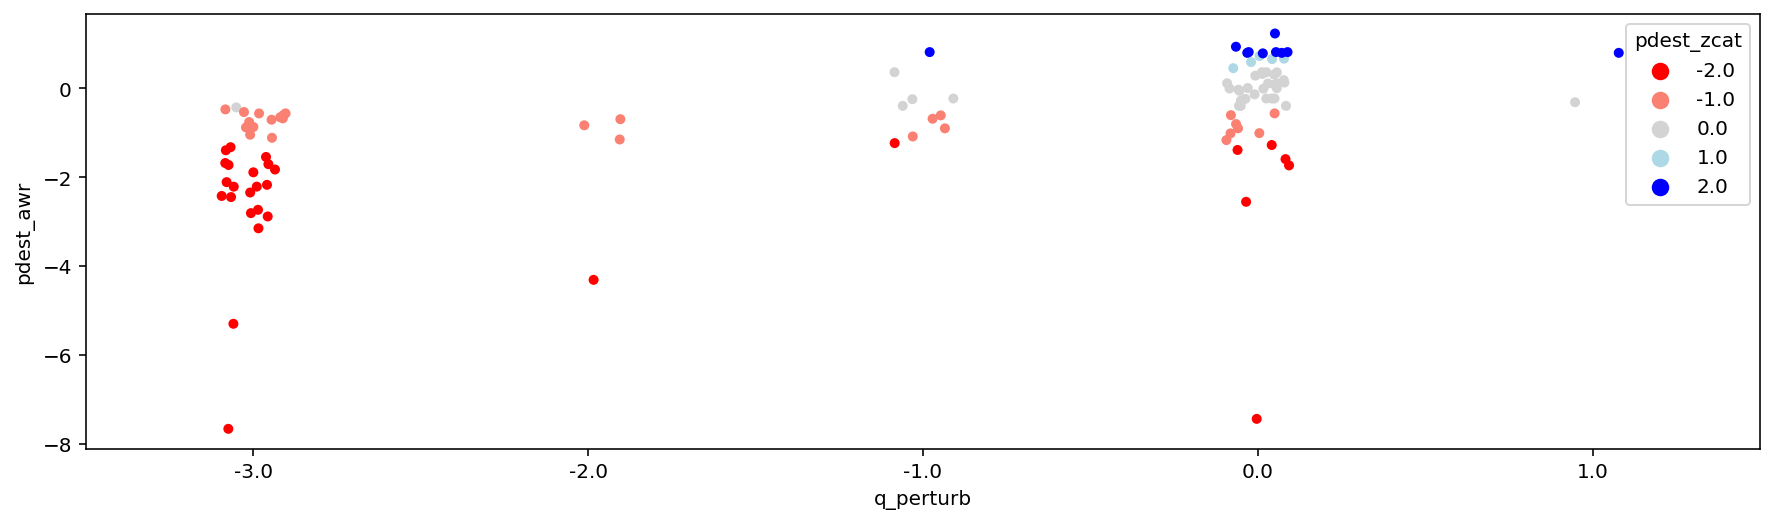

In [37]:
plt.figure(figsize=(15,4))
sns.stripplot(data=big_table[(~big_table.pdest_awr.isnull())&(big_table.mN2H_WT_pos)], 
              x='q_perturb', y=big_table.pdest_awr.apply(np.log2), 
              hue='pdest_zcat', 
              palette={-2:'red',
                       -1:'salmon',
                       0:'lightgray',
                       1:'lightblue',
                       2:'blue'}
             )
#plt.xlabel('qY2H 3AT perturbation score')
#plt.ylabel('mN2H Allele / WT (log2)')
plt.show()

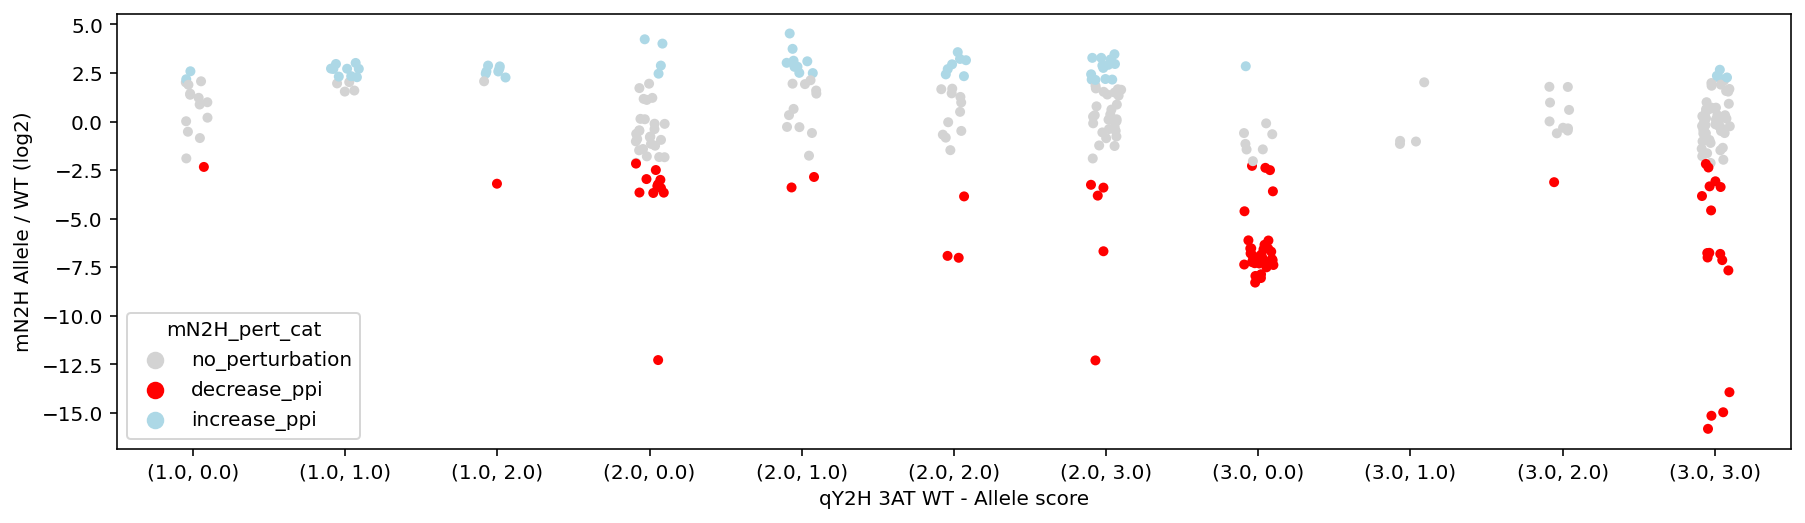

In [38]:
plt.figure(figsize=(15,4))
sns.stripplot(data=big_table[big_table.mN2H_WT_pos == True].sort_values(by='WT_Allele_q3AT'), x='WT_Allele_q3AT', y=big_table.mN2H_AWT_r.apply(np.log2),
              hue='mN2H_pert_cat', palette={'decrease_ppi':'red',
                                             'increase_ppi':'lightblue',
                                             'no_perturbation':'lightgray'}
)
             
plt.xlabel('qY2H 3AT WT - Allele score')
plt.ylabel('mN2H Allele / WT (log2)')
plt.show()

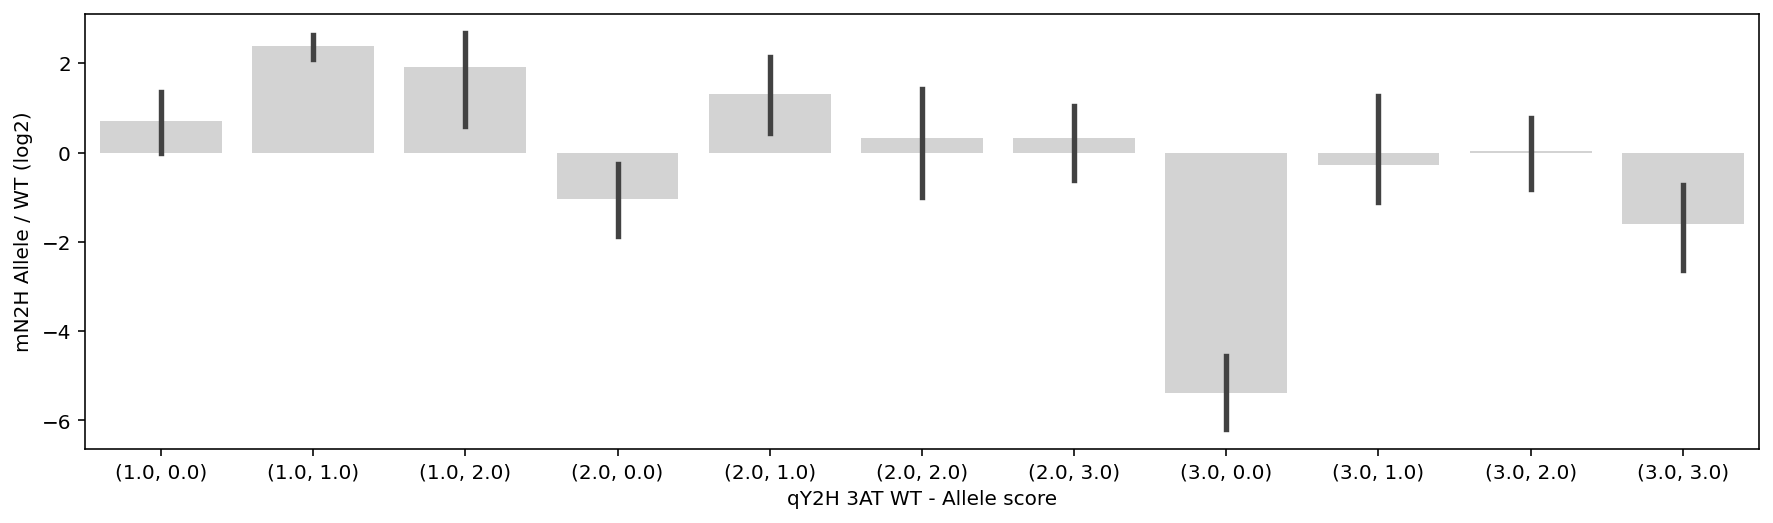

In [39]:
plt.figure(figsize=(15,4))
sns.barplot(data=big_table[big_table.mN2H_WT_pos == True].sort_values(by='WT_Allele_q3AT'), x='WT_Allele_q3AT', y=big_table.mN2H_AWT_r.apply(np.log2),color='lightgray'
)
             
plt.xlabel('qY2H 3AT WT - Allele score')
plt.ylabel('mN2H Allele / WT (log2)')
plt.show()

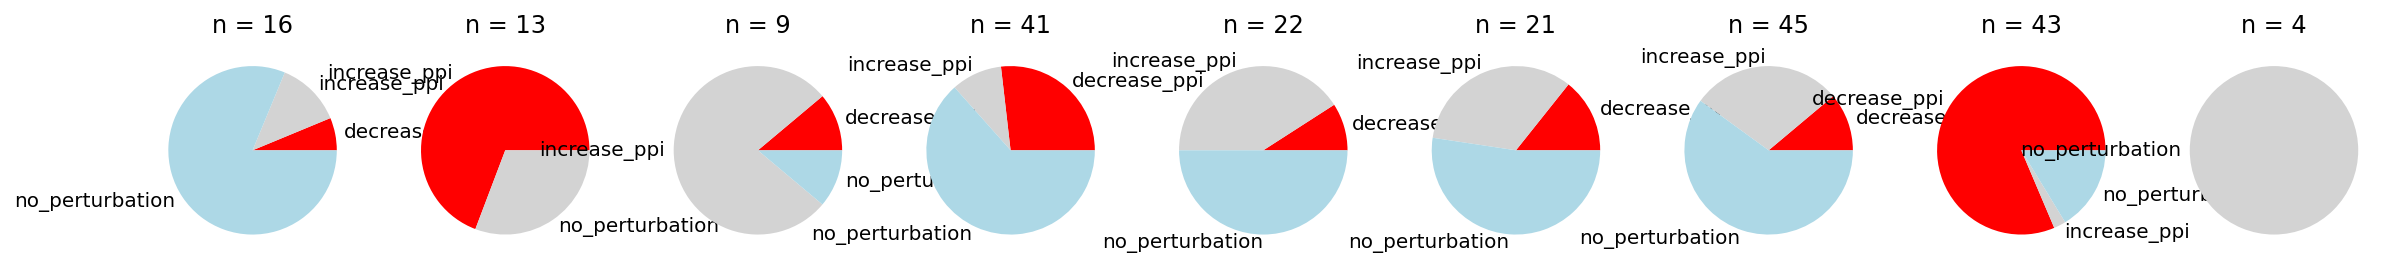

In [40]:
fig, (ax1,ax2,ax3,ax4,ax5,ax6,ax7,ax8,ax9) = plt.subplots(1, 9,figsize=(20, 20))
for ax,qpert in zip([ax1,ax2,ax3,ax4,ax5,ax6,ax7,ax8,ax9],[(1,0),(1,1),(1,2),(2,0),(2,1),(2,2),(2,3),(3,0),(3,1),(3,2),(3,3)]):
    
    ax.set_title(f'n = {len(big_table[(big_table.mN2H_WT_pos == True)&(big_table.WT_Allele_q3AT == qpert)])}')
    colors = ['red','lightgray','lightblue']
    if qpert in [(3,1)]:
        colors = ['lightgray']

        
    big_table[(big_table.mN2H_WT_pos)&(big_table.WT_Allele_q3AT == qpert)].mN2H_pert_cat.value_counts().sort_index().plot.pie(ax=ax, colors=colors)#,labeldistance=None)
    ax.set_ylabel('')
    
plt.show()

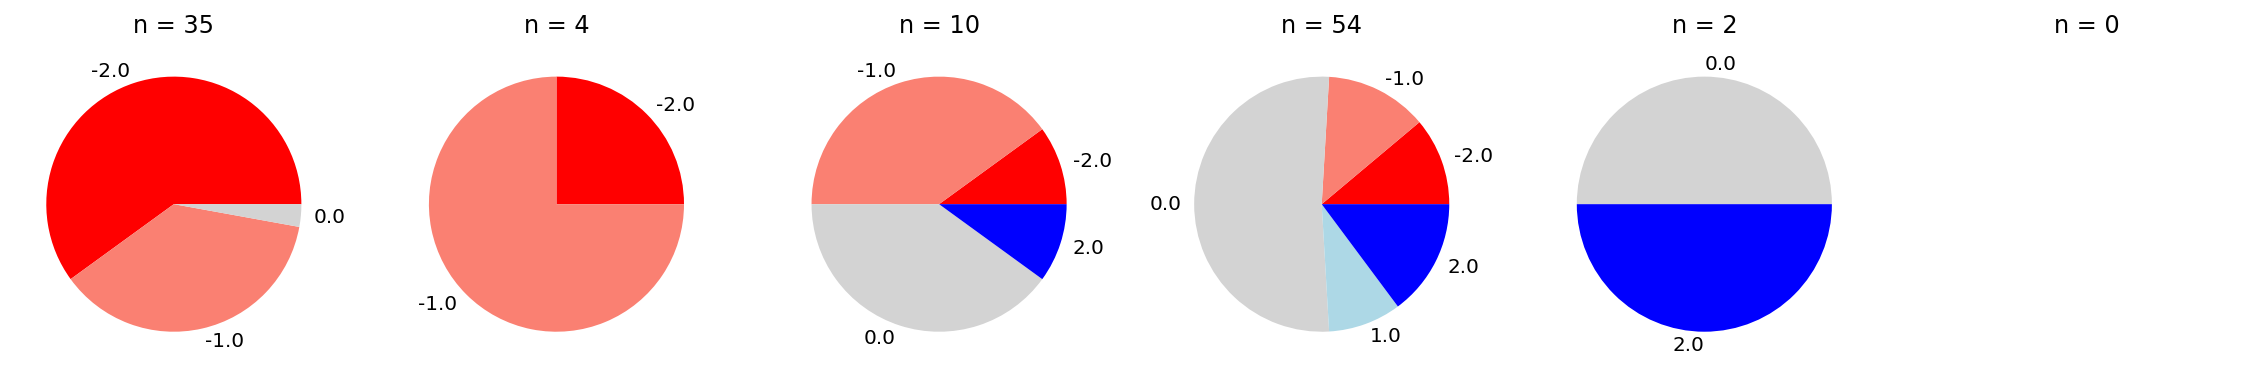

In [41]:
fig, (ax1,ax2,ax3,ax4,ax5,ax6) = plt.subplots(1, 6,figsize=(20, 20))
for ax,qpert in zip([ax1,ax2,ax3,ax4,ax5,ax6],[-3,-2,-1,0,1,2]):
    
    ax.set_title(f'n = {len(big_table[(big_table.mN2H_WT_pos)&(~big_table.pdest_awr.isnull())&(big_table.q_perturb == qpert)])}')
    colors = ['red','salmon','lightgray','lightblue','blue']
    if qpert == -1:
        colors = ['red','salmon','lightgray','blue']
    if qpert == 1:
        colors = ['lightgray','blue']
    #elif qpert == 2:
    #    colors = ['lightgray']
    #else:
    #    colors = ['red','lightblue','lightgray']
        
    big_table[(big_table.mN2H_WT_pos)&(~big_table.pdest_awr.isnull())&(big_table.q_perturb == qpert)].pdest_zcat.value_counts().sort_index().plot.pie(ax=ax, colors=colors)#,labeldistance=None)
    ax.set_ylabel('')
    
plt.show()

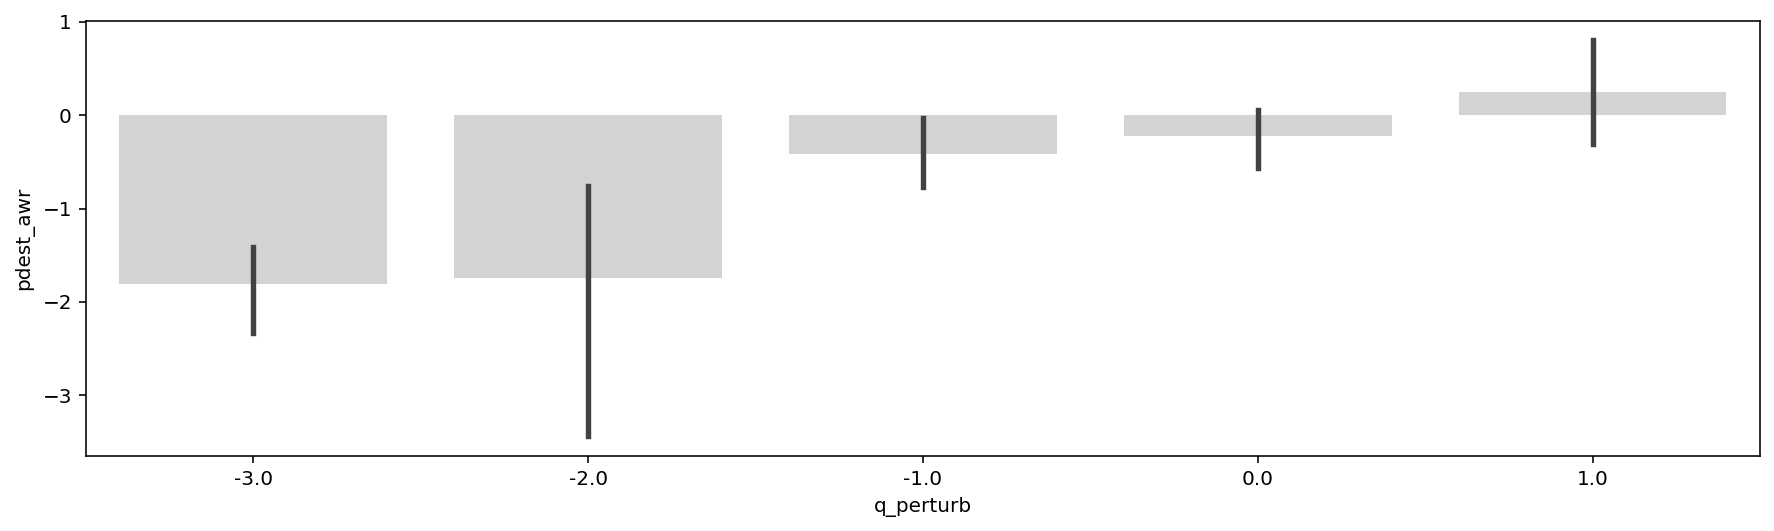

In [42]:
plt.figure(figsize=(15,4))
sns.barplot(data=big_table[(~big_table.pdest_awr.isnull())&(big_table.mN2H_WT_pos)], 
              x='q_perturb', y=big_table.pdest_awr.apply(np.log2), 
              color='lightgray'
             )
#plt.xlabel('qY2H 3AT perturbation score')
#plt.ylabel('mN2H Allele / WT (log2)')
plt.show()

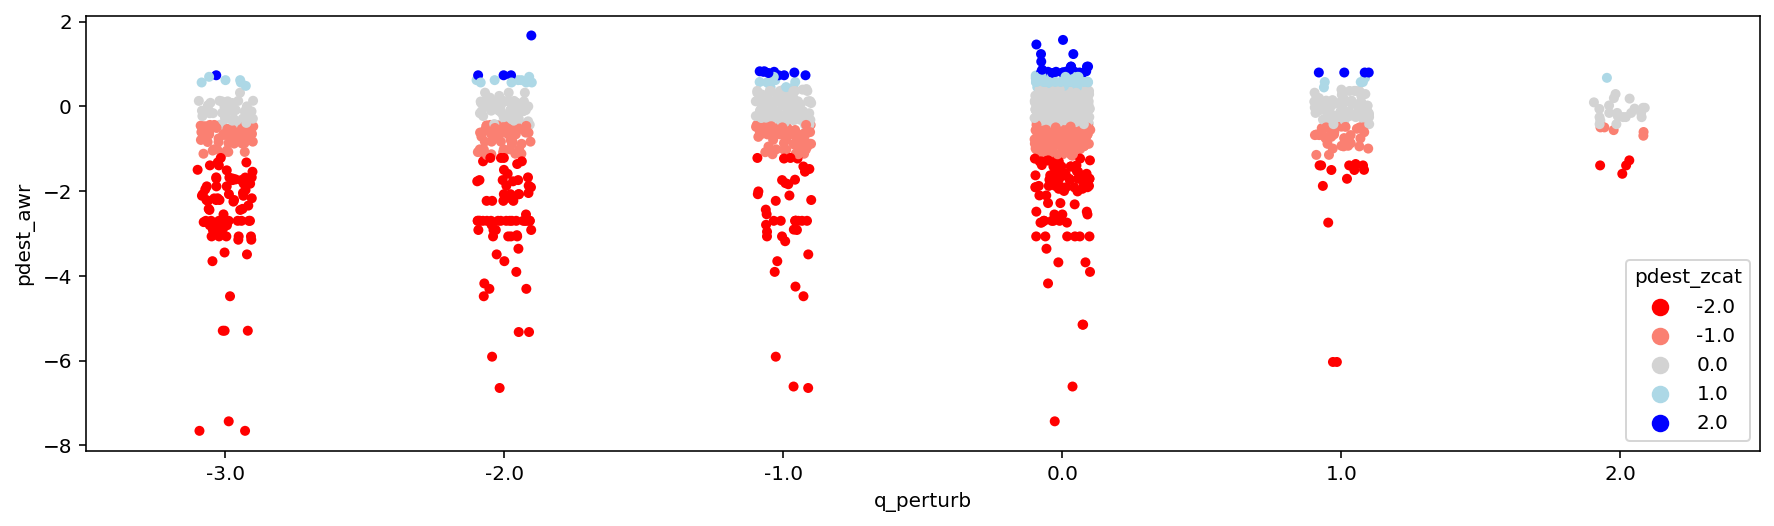

In [43]:
plt.figure(figsize=(15,4))
sns.stripplot(data=big_table[~big_table.pdest_awr.isnull()], x='q_perturb', y=big_table.pdest_awr.apply(np.log2), hue='pdest_zcat', palette={-2:'red',
                                                                                                                                             -1:'salmon',
                                                                                                                                             0:'lightgray',
                                                                                                                                             1:'lightblue',
                                                                                                                                             2:'blue'}
             )
#plt.xlabel('qY2H 3AT perturbation score')
#plt.ylabel('mN2H Allele / WT (log2)')
plt.show()

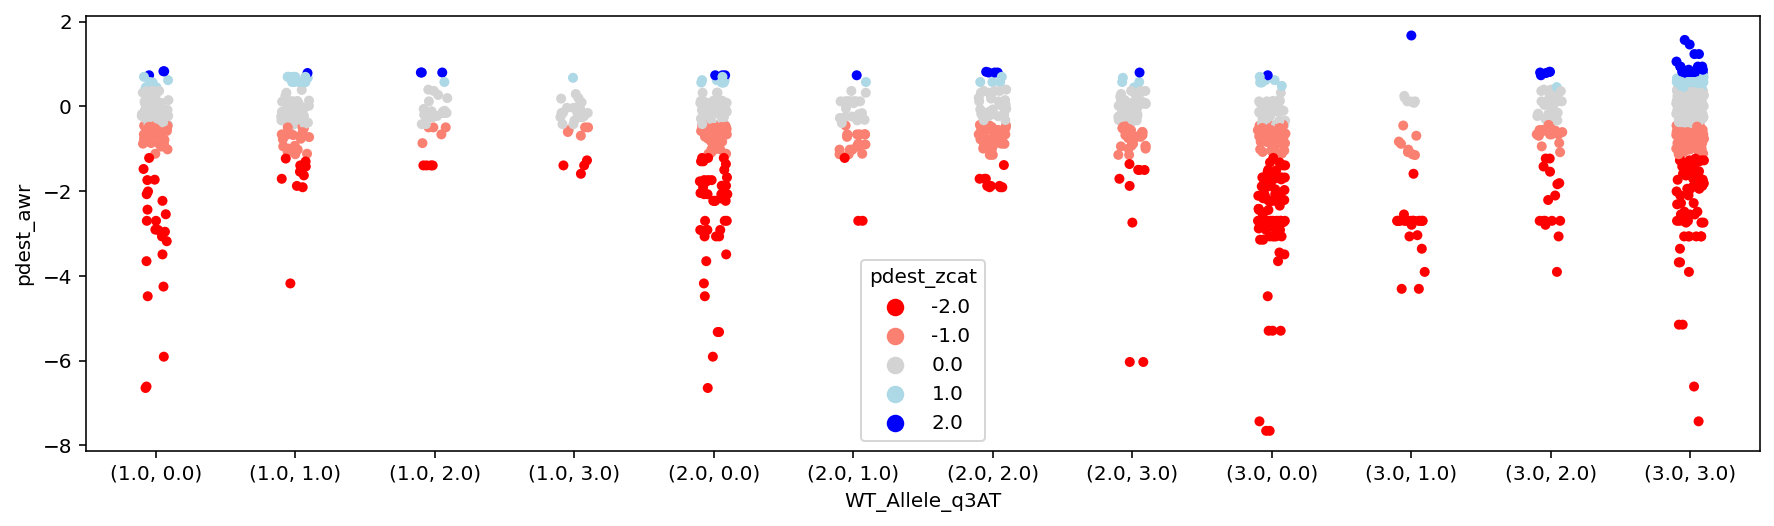

In [44]:
plt.figure(figsize=(15,4))
sns.stripplot(data=big_table[~big_table.pdest_awr.isnull()].sort_values(by='WT_Allele_q3AT'), 
              x='WT_Allele_q3AT', y=big_table.pdest_awr.apply(np.log2), hue='pdest_zcat', palette={-2:'red',
                                                                                                     -1:'salmon',
                                                                                                     0:'lightgray',
                                                                                                     1:'lightblue',
                                                                                                     2:'blue'}
             )
#plt.xlabel('qY2H 3AT perturbation score')
#plt.ylabel('mN2H Allele / WT (log2)')
plt.show()

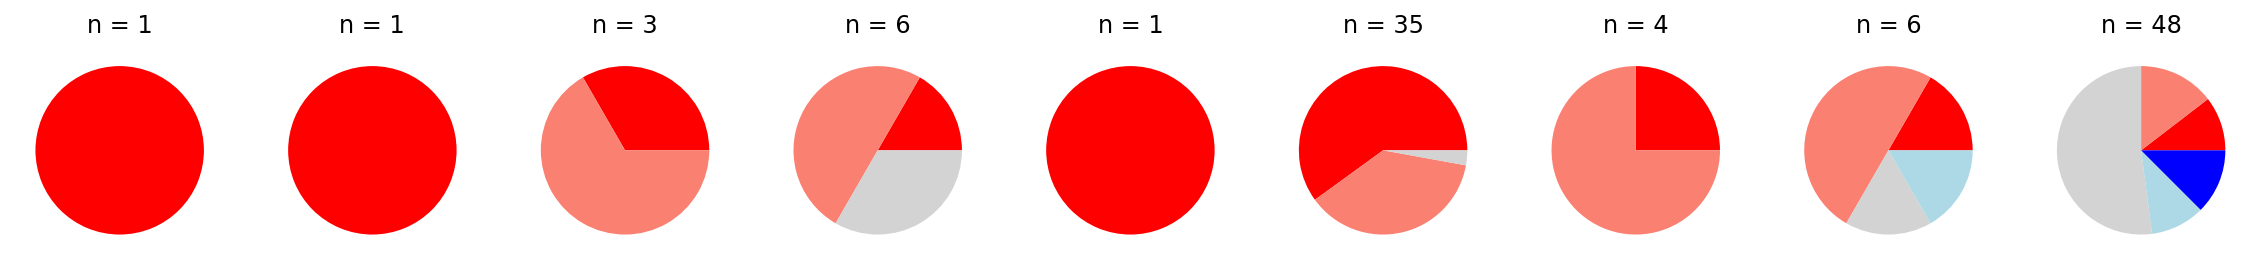

In [45]:
fig, (ax1,ax2,ax3,ax4,ax5,ax6,ax7,ax8,ax9) = plt.subplots(1, 9,figsize=(20, 20))
for ax,qpert in zip([ax1,ax2,ax3,ax4,ax5,ax6,ax7,ax8,ax9],[(1,0),(1,2),(2,1),(2,2),(2,3),(3,0),(3,1),(3,2),(3,3)]):
    
    ax.set_title(f'n = {len(big_table[(big_table.mN2H_WT_pos)&(~big_table.pdest_awr.isnull())&(big_table.WT_Allele_q3AT == qpert)])}')
    colors = ['red','salmon','lightgray','lightblue','blue']
    if qpert in [(1,3)]:
        colors=['red','salmon','lightgray','lightblue']
        
    if qpert in [(1,3)]:
        colors=['red','salmon','lightgray','lightblue']

    #elif qpert == 2:
    #    colors = ['lightgray']
    #else:
    #    colors = ['red','lightblue','lightgray']
        
    big_table[(big_table.mN2H_WT_pos)&(~big_table.pdest_awr.isnull())&(big_table.WT_Allele_q3AT == qpert)].pdest_zcat.value_counts().sort_index().plot.pie(ax=ax, colors=colors,labeldistance=None)
    ax.set_ylabel('')
    
plt.show()

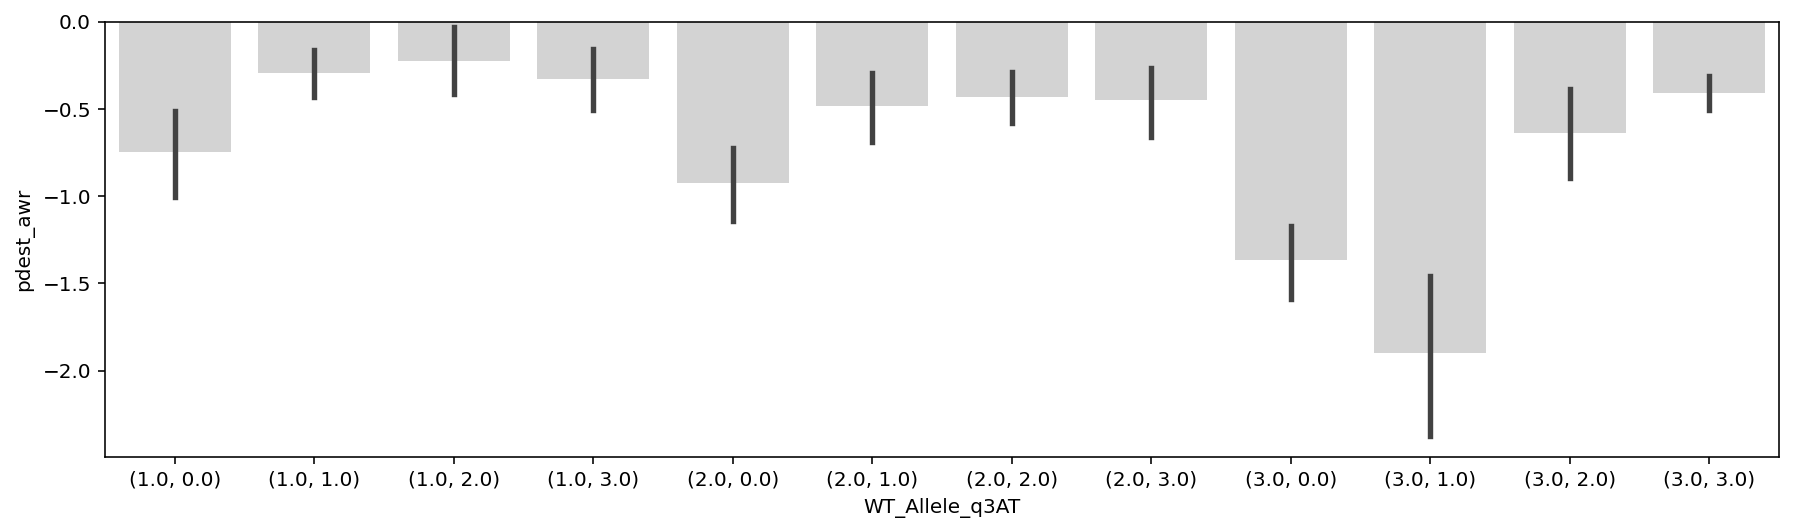

In [46]:
plt.figure(figsize=(15,4))
sns.barplot(data=big_table[~big_table.pdest_awr.isnull()].sort_values(by='WT_Allele_q3AT'), 
              x='WT_Allele_q3AT', y=big_table.pdest_awr.apply(np.log2), color='lightgray'
             )
#plt.xlabel('qY2H 3AT perturbation score')
#plt.ylabel('mN2H Allele / WT (log2)')
plt.show()

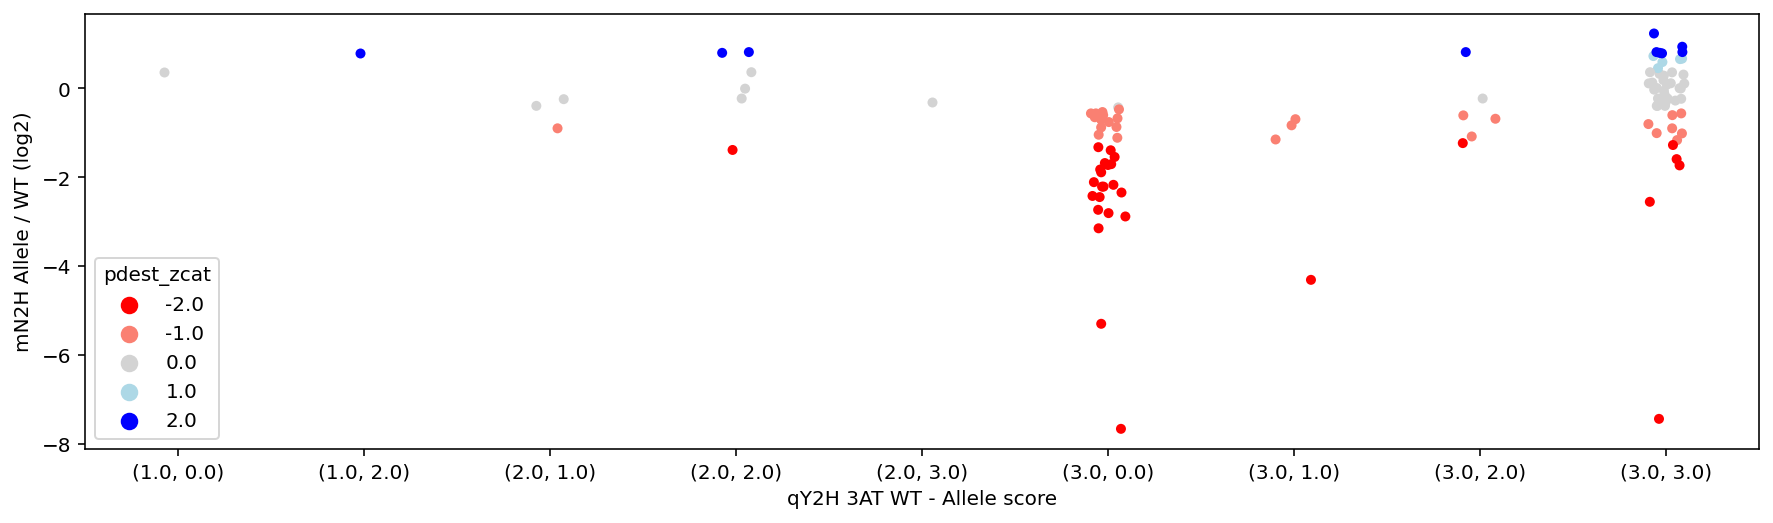

In [47]:
plt.figure(figsize=(15,4))
sns.stripplot(data=big_table[(~big_table.pdest_awr.isnull())&(big_table.mN2H_WT_pos)].sort_values(by='WT_Allele_q3AT'), 
              x='WT_Allele_q3AT',y=big_table.pdest_awr.apply(np.log2), 
              hue='pdest_zcat', palette={-2:'red',
                       -1:'salmon',
                       0:'lightgray',
                       1:'lightblue',
                       2:'blue'}
             )
plt.xlabel('qY2H 3AT WT - Allele score')
plt.ylabel('mN2H Allele / WT (log2)')
plt.show()

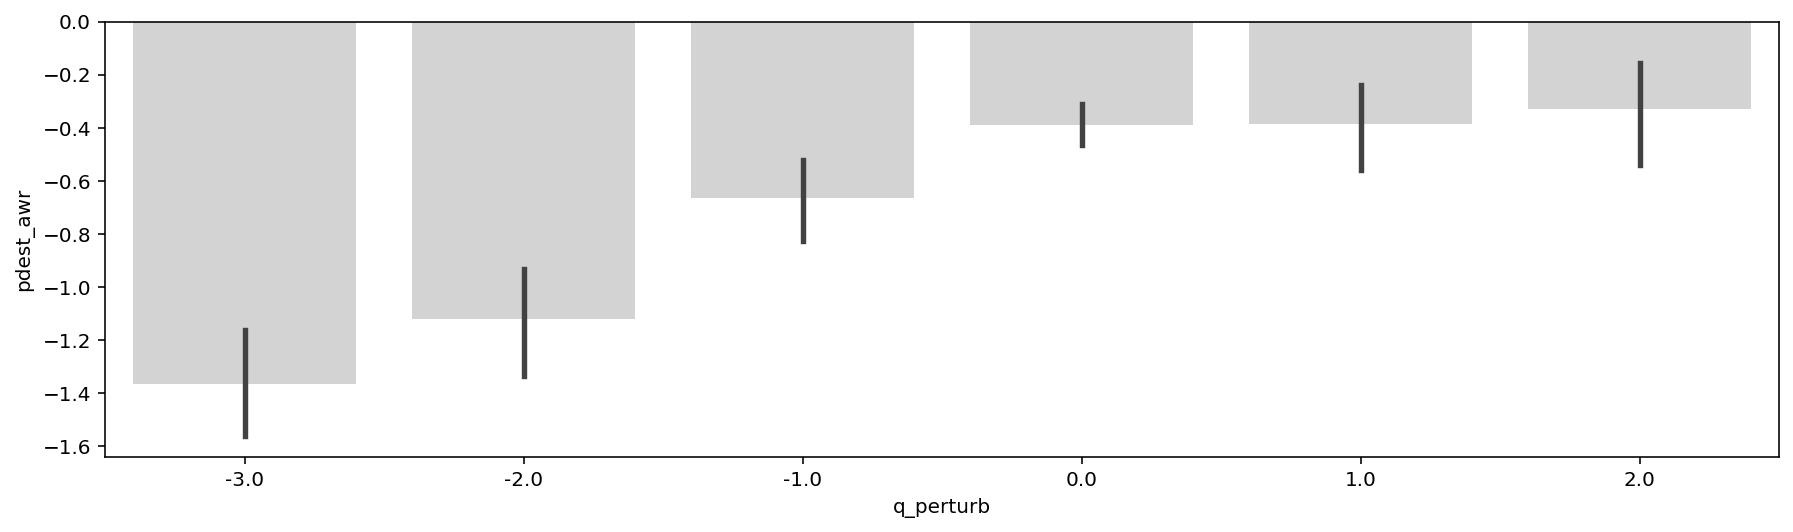

In [48]:
plt.figure(figsize=(15,4))
sns.barplot(data=big_table[~big_table.pdest_awr.isnull()], x='q_perturb', y=big_table.pdest_awr.apply(np.log2), color='lightgray'
             )
#plt.xlabel('qY2H 3AT perturbation score')
#plt.ylabel('mN2H Allele / WT (log2)')
plt.show()

In [49]:
big_table[~big_table.pdest_awr.isnull()]

,ad_orf_id,db_orf_id,orf_pair,db_mut_id,assay_id,LW,LWH1,LWH10,LWH25,LWA,LWAH1,sum_score,n_condition,allele_score_norm,wt_score_norm,valid,nt_change,aa_change,clinical_significance,db_symbol,ad_symbol,NLR,avg_NLR_mN2H,avg_NLR_yN2H,d_nanoY2H,pdest_ratio,pdest_zscore,pdest_zcat,d_mN2H,d_yN2H,d_ade,d_his1,d_his10,d_his25,q3AT,WT_q3AT,n_media_q3AT,n_syst,lit_bm,lit_bs,perturb_class,q_perturb,mN2H_AWT_r,mN2H_WT_pos,mN2H_pert_cat,pdest_awr,WT_Allele_q3AT
82,2099.0,70497.0,"(70497.0, 2099.0)",3780.0,1.0,"[4.0, 4.0, True]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",0.0,5.0,0.0,0.6,True,28C>G,Pro10Ala,VUS,AGXT,RFX6,0.553038,NaN,NaN,False,1.537723,1.606791,1.0,False,False,False,False,False,False,0.0,3.0,3.0,0,False,False,P,-3.0,NaN,NaN,NaN,1.537723,"(3.0, 0.0)"
83,71959.0,70497.0,"(70497.0, 71959.0)",3780.0,1.0,"[4.0, 4.0, True]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",0.0,5.0,0.0,0.4,True,28C>G,Pro10Ala,VUS,AGXT,KRTAP1-1,0.688328,NaN,NaN,False,1.537723,1.606791,1.0,False,False,False,False,False,False,0.0,2.0,3.0,0,False,False,P,-2.0,NaN,NaN,NaN,1.537723,"(2.0, 0.0)"
84,56141.0,70497.0,"(70497.0, 56141.0)",3780.0,1.0,"[4.0, 4.0, True]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",0.0,5.0,0.0,0.4,True,28C>G,Pro10Ala,VUS,AGXT,KRT31,-1.199375,NaN,NaN,False,1.537723,1.606791,1.0,False,False,False,False,False,False,0.0,2.0,3.0,0,False,False,P,-2.0,NaN,NaN,NaN,1.537723,"(2.0, 0.0)"
85,13662.0,70497.0,"(70497.0, 13662.0)",3780.0,1.0,"[4.0, 4.0, True]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",0.0,5.0,0.0,1.0,True,28C>G,Pro10Ala,VUS,AGXT,CYSRT1,NaN,NaN,NaN,False,1.537723,1.606791,1.0,False,False,False,False,False,False,0.0,3.0,3.0,0,False,False,P,-3.0,NaN,NaN,NaN,1.537723,"(3.0, 0.0)"
86,54668.0,70497.0,"(70497.0, 54668.0)",3780.0,1.0,"[4.0, 4.0, True]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",0.0,5.0,0.0,0.4,True,28C>G,Pro10Ala,VUS,AGXT,KRT40,0.763592,NaN,NaN,False,1.537723,1.606791,1.0,False,False,False,False,False,False,0.0,2.0,3.0,0,False,False,P,-2.0,NaN,NaN,NaN,1.537723,"(2.0, 0.0)"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4521,778.0,7675.0,"(7675.0, 778.0)",202590.0,2.0,"[3.0, 4.0, True]","[3.0, 0.0, 1]","[4.0, 0.0, 1]","[4.0, 0.0, 1]","[3.0, 0.0, 1]","[3.0, 0.0, 1]",5.0,5.0,1.0,1.0,True,457C>G,Leu153Val,Pathogenic,NMNAT1,KPNA6,5.630362,NaN,NaN,True,1.006644,-0.128938,0.0,False,False,True,True,True,True,3.0,3.0,3.0,2,False,False,NP,0.0,NaN,NaN,NaN,1.006644,"(3.0, 3.0)"
4524,778.0,7675.0,"(7675.0, 778.0)",202587.0,2.0,"[3.0, 4.0, True]","[3.0, 0.0, 1]","[4.0, 0.0, 1]","[4.0, 0.0, 1]","[4.0, 0.0, 1]","[4.0, 0.0, 1]",5.0,5.0,1.0,1.0,True,817A>G,Asn273Asp,Pathogenic,NMNAT1,KPNA6,5.964558,NaN,NaN,True,0.993905,-0.170575,0.0,False,False,True,True,True,True,3.0,3.0,3.0,2,False,False,NP,0.0,NaN,NaN,NaN,0.993905,"(3.0, 3.0)"
4526,778.0,7675.0,"(7675.0, 778.0)",202588.0,2.0,"[3.0, 4.0, True]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",0.0,5.0,0.0,1.0,True,710G>T,Arg237Leu,Pathogenic,NMNAT1,KPNA6,0.874077,NaN,NaN,False,0.025513,-3.335576,-2.0,False,False,False,False,False,False,0.0,3.0,3.0,0,False,False,P,-3.0,NaN,NaN,NaN,0.025513,"(3.0, 0.0)"
4528,778.0,7675.0,"(7675.0, 778.0)",202585.0,2.0,"[3.0, 4.0, True]","[3.0, 0.0, 1]","[4.0, 0.0, 1]","[4.0, 0.0, 1]","[4.0, 0.0, 1]","[4.0, 0.0, 1]",5.0,5.0,1.0,1.0,True,769G>A,Glu257Lys,Pathogenic,NMNAT1,KPNA6,7.223273,NaN,NaN,True,1.061268,0.049591,0.0,False,False,True,True,True,True,3.0,3.0,3.0,2,False,False,NP,0.0,NaN,NaN,NaN,1.061268,"(3.0, 3.0)"


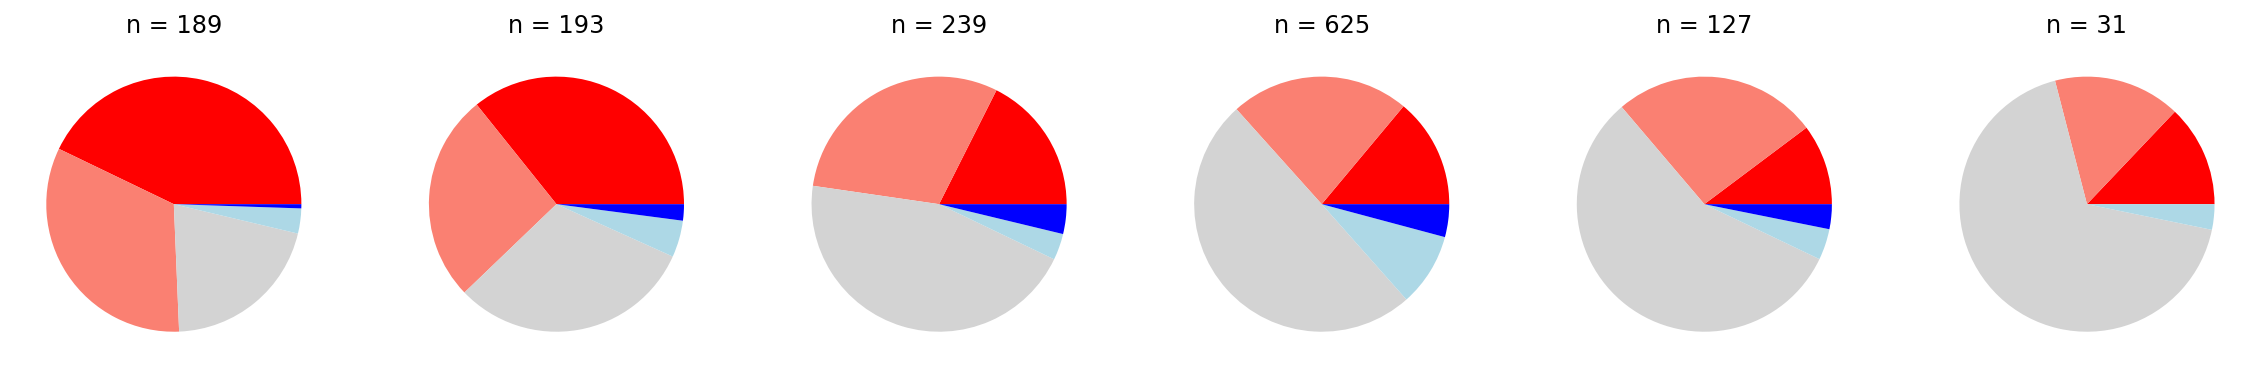

In [50]:
fig, (ax1,ax2,ax3,ax4,ax5,ax6) = plt.subplots(1, 6,figsize=(20, 20))
for ax,qpert in zip([ax1,ax2,ax3,ax4,ax5,ax6],[-3,-2,-1,0,1,2]):
    
    ax.set_title(f'n = {len(big_table[~big_table.pdest_awr.isnull()&(big_table.q_perturb == qpert)])}')
    colors = ['red','salmon','lightgray','lightblue','blue']
    #if qpert == -3:
    #    colors = ['red','salmon','lightgray','lightblue','blue']
    #elif qpert == 2:
    #    colors = ['lightgray']
    #else:
    #    colors = ['red','lightblue','lightgray']
        
    big_table[(~big_table.pdest_awr.isnull())&(big_table.q_perturb == qpert)].pdest_zcat.value_counts().sort_index().plot.pie(ax=ax, colors=colors,labeldistance=None)
    ax.set_ylabel('')
    
plt.show()

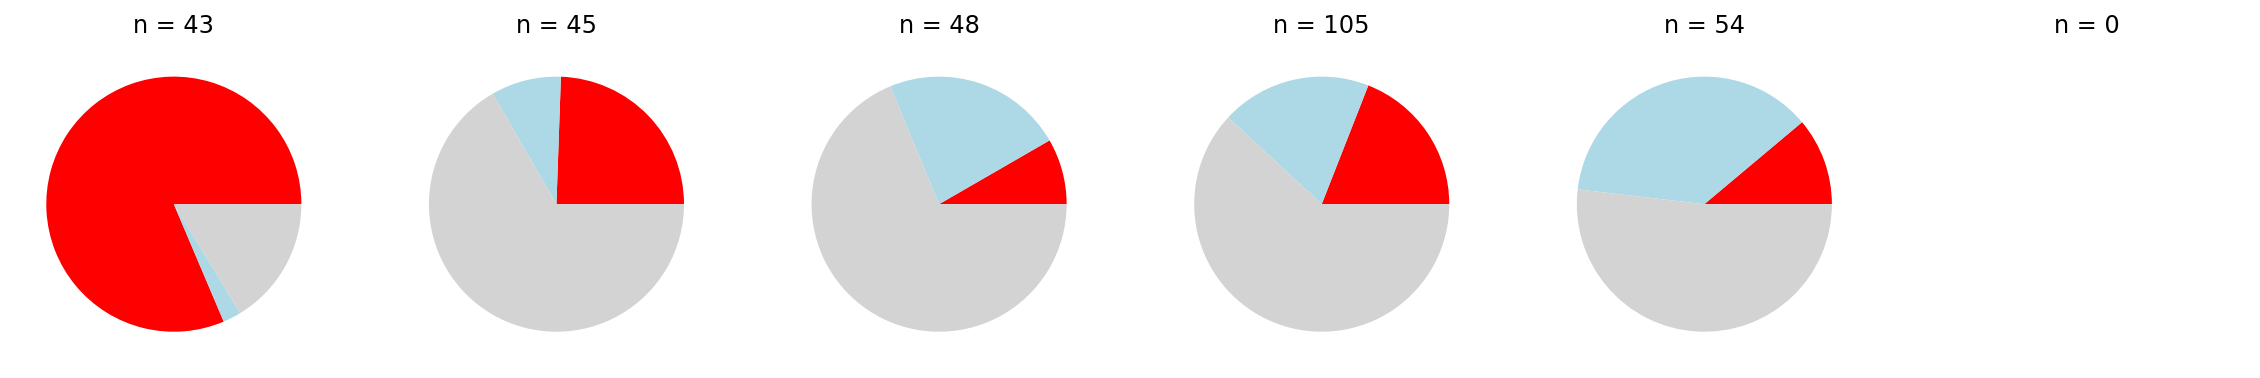

In [51]:
fig, (ax1,ax2,ax3,ax4,ax5,ax6) = plt.subplots(1, 6,figsize=(20, 20))
for ax,qpert in zip([ax1,ax2,ax3,ax4,ax5,ax6],[-3,-2,-1,0,1,2]):
    ax.set_title(f'n = {len(big_table[(big_table.mN2H_WT_pos == True)&(big_table.q_perturb == qpert)])}')
    if qpert == -3:
        colors = ['red','lightblue','lightgray']
    elif qpert == 2:
        colors = ['lightgray']
    else:
        colors = ['red','lightblue','lightgray']
        
    big_table[(big_table.mN2H_WT_pos == True)&(big_table.q_perturb == qpert)].mN2H_pert_cat.value_counts().sort_index().plot.pie(ax=ax, colors=colors,labeldistance=None)
    ax.set_ylabel('')
    
plt.show()

In [52]:
big_table[(big_table.mN2H_WT_pos == True)&(big_table.q_perturb == -3)].db_orf_id.nunique()

8

In [53]:
big_table[(big_table.mN2H_WT_pos == True)&(big_table.q_perturb == -3)&(big_table.clinical_significance == 'Benign')]

,ad_orf_id,db_orf_id,orf_pair,db_mut_id,assay_id,LW,LWH1,LWH10,LWH25,LWA,LWAH1,sum_score,n_condition,allele_score_norm,wt_score_norm,valid,nt_change,aa_change,clinical_significance,db_symbol,ad_symbol,NLR,avg_NLR_mN2H,avg_NLR_yN2H,d_nanoY2H,pdest_ratio,pdest_zscore,pdest_zcat,d_mN2H,d_yN2H,d_ade,d_his1,d_his10,d_his25,q3AT,WT_q3AT,n_media_q3AT,n_syst,lit_bm,lit_bs,perturb_class,q_perturb,mN2H_AWT_r,mN2H_WT_pos,mN2H_pert_cat,pdest_awr,WT_Allele_q3AT
687,2533.0,55246.0,"(55246.0, 2533.0)",3236.0,1.0,"[4.0, 4.0, True]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",0.0,5.0,0.0,0.6,True,176C>T,Thr59Met,Benign,PYGL,PYGB,0.507347,220.761471,16.656941,False,0.744286,-0.986406,0.0,True,True,False,False,False,False,0.0,3.0,3.0,2,False,False,P,-3.0,0.936946,True,no_perturbation,0.744286,"(3.0, 0.0)"
1628,6281.0,100016069.0,"(100016069.0, 6281.0)",2635.0,6.0,"[3.0, 3.0, True]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, nan, nan]","[0.0, 0.0, 0]",0.0,4.0,0.0,0.6,True,773T>C,Ile258Thr,Benign,KCNJ2,KCNJ15,-0.012270,3.920659,0.854091,False,0.659611,-1.263151,-1.0,False,True,False,False,False,False,0.0,3.0,3.0,1,False,False,P,-3.0,0.008643,True,decrease_ppi,0.659611,"(3.0, 0.0)"
3364,361.0,3438.0,"(3438.0, 361.0)",201181.0,1.0,"[4.0, 4.0, True]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",0.0,5.0,0.0,0.6,True,934C>T,Arg312Trp,Benign,TMEM43,GRAMD2B,-0.839017,34.883839,0.655452,False,NaN,NaN,0.0,True,True,False,False,False,False,0.0,3.0,3.0,2,False,False,P,-3.0,0.370325,True,no_perturbation,NaN,"(3.0, 0.0)"


In [54]:
df = big_table[(big_table.mN2H_WT_pos == True)&(big_table.q_perturb == -3)]

pd.Series(zip(df.db_orf_id, df.ad_orf_id)).unique()

array([(55246.0, 2533.0), (100016069.0, 6281.0), (13939.0, 71152.0),
       (9726.0, 13954.0), (9726.0, 54326.0), (3438.0, 361.0),
       (7675.0, 7675.0), (2654.0, 2654.0), (3731.0, 3731.0)], dtype=object)

In [55]:
big_table[(big_table.mN2H_WT_pos == True)&(big_table.q_perturb == -3)].mN2H_pert_cat.value_counts()

decrease_ppi       35
no_perturbation     7
increase_ppi        1
Name: mN2H_pert_cat, dtype: int64

In [56]:
plt.figure(figsize=(15,4))
sns.barplot(data=big_table[big_table.yN2H_WT_pos == True], 
            x='q_perturb', 
            y=big_table[big_table.yN2H_WT_pos == True].yN2H_pert_cat.apply(lambda x: np.nan if x != x else 1 if x == 'decrease_ppi' else 0),
            color='gray', capsize=0.05
           )
plt.xlabel('qY2H 3AT perturbation score')
plt.ylabel('PPI perturbing fraction')
plt.show()

AttributeError: 'DataFrame' object has no attribute 'yN2H_WT_pos'

<Figure size 1080x288 with 0 Axes>

In [ ]:
from load_edgotyping_data import load_qY2H


load_qY2H()

In [57]:
big_table.head()

,ad_orf_id,db_orf_id,orf_pair,db_mut_id,assay_id,LW,LWH1,LWH10,LWH25,LWA,LWAH1,sum_score,n_condition,allele_score_norm,wt_score_norm,valid,nt_change,aa_change,clinical_significance,db_symbol,ad_symbol,NLR,avg_NLR_mN2H,avg_NLR_yN2H,d_nanoY2H,pdest_ratio,pdest_zscore,pdest_zcat,d_mN2H,d_yN2H,d_ade,d_his1,d_his10,d_his25,q3AT,WT_q3AT,n_media_q3AT,n_syst,lit_bm,lit_bs,perturb_class,q_perturb,mN2H_AWT_r,mN2H_WT_pos,mN2H_pert_cat,pdest_awr,WT_Allele_q3AT
0,54326.0,7323.0,"(7323.0, 54326.0)",0.0,1.0,"[4.0, 4.0, True]","[3.0, 0.0, 1]","[2.0, 0.0, 1]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",2.0,5.0,0.4,0.4,True,WT,WT,WT,PMP22,EDA,-0.07968,1.370158,NaN,False,NaN,NaN,NaN,False,True,False,True,True,False,2.0,2.0,3.0,1,False,False,NP,0.0,NaN,NaN,NaN,NaN,"(2.0, 2.0)"
1,581.0,13295.0,"(13295.0, 581.0)",0.0,1.0,"[4.0, 4.0, True]","[2.0, 0.0, 1]","[2.0, 0.0, 1]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",2.0,5.0,0.4,0.4,True,WT,WT,WT,TTPA,MAL2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,False,False,True,True,False,2.0,2.0,3.0,0,False,False,NP,0.0,NaN,NaN,NaN,NaN,"(2.0, 2.0)"
2,869.0,13295.0,"(13295.0, 869.0)",0.0,1.0,"[4.0, 4.0, True]","[3.0, 0.0, 1]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",1.0,5.0,0.2,0.2,True,WT,WT,WT,TTPA,CMTM5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,False,False,True,False,False,1.0,1.0,3.0,0,False,False,NP,0.0,NaN,NaN,NaN,NaN,"(1.0, 1.0)"
3,7606.0,13295.0,"(13295.0, 7606.0)",0.0,1.0,"[4.0, 4.0, True]","[4.0, 0.0, 1]","[3.0, 0.0, 1]","[4.0, 0.0, 1]","[2.0, 0.0, 1]","[3.0, 0.0, 1]",5.0,5.0,1.0,1.0,True,WT,WT,WT,TTPA,BIRC7,NaN,NaN,0.57692,NaN,NaN,NaN,NaN,False,False,True,True,True,True,3.0,3.0,3.0,1,False,False,NP,0.0,NaN,NaN,NaN,NaN,"(3.0, 3.0)"
4,7845.0,13295.0,"(13295.0, 7845.0)",0.0,1.0,"[4.0, 4.0, True]","[3.0, 0.0, 1]","[3.0, 0.0, 1]","[0.0, 0.0, 0]","[0.0, 0.0, 0]","[0.0, 0.0, 0]",2.0,5.0,0.4,0.4,True,WT,WT,WT,TTPA,AGTRAP,-0.65793,NaN,NaN,False,NaN,NaN,NaN,False,False,False,True,True,False,2.0,2.0,3.0,0,False,False,NP,0.0,NaN,NaN,NaN,NaN,"(2.0, 2.0)"
